# 31 Netz: Leitungen, Hausstationen, Zähler und Kanten

Teil 7: Netz

**Worum es geht**
- Aus Leitungsplan, Kantendatei und Zählerlisten ein Netzmodell bauen: welche Station hängt wo am Netz.
- HAST = Hausübergabestation, also die Station im Haus mit dem Wärmezähler.
- Zähler mit Zeitreihe auf Knoten, Kanten und Karte bringen und die Datenqualität prüfen.
- Das Ergebnis ist die Grundlage für die Notebooks 32 (Einspeisung), 33 (Netzkarte), 36 (Dashboard) und 38 (GNN).

**Daten**
- liest: `data/raw/Leitungsverlauf/` (Shapefiles), `data/raw/Leitungsverlauf.kml`, `data/raw/Nodes_Edges.ods`, `data/raw/Zuordnung.xlsx`, `data/manual/adressen_koordinaten.ods` (früher `data/processed/`, wird weiter gelesen), `data/processed/real_meters/`
- schreibt: in `notebooks/` mehrere CSV-Tabellen (z. B. `hast_zaehler.csv`, `kanten_roh_bereinigt.csv`, `kanten_auf_rohren.csv`, `hast_positionen.csv`, `geocode_cache.csv`), Bilder, `fehlende_koordinaten_<Zeit>.ods`, `daten_cache/paket.pkl` und über `dashboard_export.py` die Datei `fernwaerme_dashboard.html`
- vorher ausführen: Notebook 00 (Zeitreihen in `real_meters`)
- Ausgaben und Dateien enthalten Adressen. Sie bleiben intern.

**Code**
- Hilfsfunktionen stehen im Notebook, der Dashboard-Export in `notebooks/dashboard_export.py`.
- Arbeitsverzeichnis ist `notebooks/`. Zusätzlich zu `requirements.txt` wird `geopy` nur für die optionale Nominatim-Suche gebraucht.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import re
import difflib
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
import pyogrio
import shapely
from folium.plugins import PolyLineTextPath
from shapely import force_2d
from shapely.geometry import LineString, Point
from shapely.ops import substring, unary_union
from io import StringIO
import matplotlib.dates as mdates
import folium, branca

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 200)

DATA_RAW    = Path("..") / "data" / "raw"
SHP_ORDNER  = DATA_RAW / "Leitungsverlauf"
KML_PFAD    = DATA_RAW / "Leitungsverlauf.kml"
NODES_EDGES = DATA_RAW / "Nodes_Edges.ods"
ZUORDNUNG   = DATA_RAW / "Zuordnung.xlsx"
REAL_METERS = Path("..") / "data" / "processed" / "real_meters"

CRS_UTM = 25832                                          #ETRS89 / UTM 32N, wie die Shapefiles
CSV = dict(sep=";", index=False, encoding="utf-8-sig")   #Einstellungen für alle CSV-Exporte

## 1 Hilfsfunktionen

- Spalten in den Tabellen über Namen oder Stichworte finden.
- Adressen und Zählernummern vereinheitlichen, damit die Listen zusammenpassen.
- Die Funktionen werden in allen folgenden Abschnitten genutzt.

In [2]:
UMLAUTE = {"ß": "ss", "ä": "ae", "ö": "oe", "ü": "ue"}


def spaltenname(c):
    return re.sub(r"\s+", " ", str(c)).strip().lower()


def finde_spalte(df, name=None, stichworte=()):
    """Spalte über den genauen Namen finden, sonst über das erste passende Stichwort."""
    cols = {spaltenname(c): c for c in df.columns}
    if name and spaltenname(name) in cols:
        return cols[spaltenname(name)]
    return next((c for c in df.columns if any(s in spaltenname(c) for s in stichworte)), None)


def norm_adresse(s):
    """Vergleichsschlüssel für Adressen, z.B. 'Hauptstr. 12 a' -> 'hauptstrasse 12a'."""
    s = str(s).strip().lower()
    for a, b in UMLAUTE.items():
        s = s.replace(a, b)
    s = re.sub(r"str\.", "strasse", s)
    s = re.sub(r"[^\w\s-]", " ", s)
    s = re.sub(r"str(?=\s|$)", "strasse", s)
    s = re.sub(r"\s+", " ", s).strip()
    return re.sub(r"(\d+)\s+([a-z])\b", r"\1\2", s)


def adress_key(s):
    """norm_adresse für Tabellenzellen, leere Zellen ergeben None."""
    return norm_adresse(s) if isinstance(s, str) and s.strip() else None


def nur_strasse(s):
    """Adressschlüssel ohne Hausnummer (auch ohne Bereiche wie '12-14')."""
    return norm_adresse(re.sub(r"\s*\d+\s*[a-zA-Z]?(\s*[-/–]\s*\d+\s*[a-zA-Z]?)?\s*$", "", str(s).strip()))


def teile_adresse(a):
    """'Hauptstraße 12 a' -> ('Hauptstraße', '12a')"""
    m = re.match(r"^(.*?\D)\s*(\d+\s*[a-zA-Z]?)\s*$", re.sub(r"\s+", " ", str(a)).strip())
    return (m.group(1).strip(" ,"), m.group(2).replace(" ", "")) if m else (str(a), "")


def norm_z(s):
    """Zählernummer: nur Ziffern, ohne führende Nullen."""
    return re.sub(r"\D", "", str(s)).lstrip("0")


def zahl_sauber(x):
    """Zahlen-Spalte als Text ohne angehängtes '.0'."""
    return x.fillna("").str.strip().str.replace(r"\.0$", "", regex=True)


def dn_klasse(dn, dn_klein):
    if pd.isna(dn):
        return "unbekannt"
    return f"klein (≤ DN {dn_klein})" if dn <= dn_klein else "groß"


def parse_koordinate(s):
    """'49.81, 10.34' oder '49,81234 10,34567' -> (lat, lon), sonst (None, None)."""
    if not isinstance(s, str) or not s.strip():
        return (None, None)
    teile = [x.strip() for x in s.strip().replace(";", ",").split(",")]
    try:
        if len(teile) == 2:
            return float(teile[0]), float(teile[1])
        zahlen = re.findall(r"-?\d+(?:[.,]\d+)?", s)
        if len(zahlen) == 2:
            return tuple(float(z.replace(",", ".")) for z in zahlen)
    except ValueError:
        pass
    return (None, None)


def punkte_gdf(df):
    """GeoDataFrame (WGS84) aus den Spalten lat/lon."""
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["lon"], df["lat"]), crs=4326)


def karte_abschliessen(m, bounds, datei=None):
    """Ebenen-Auswahl, Ausschnitt auf bounds (minx, miny, maxx, maxy in WGS84), optional als HTML speichern."""
    folium.LayerControl(collapsed=False).add_to(m)
    m.fit_bounds([[bounds[1], bounds[0]], [bounds[3], bounds[2]]])
    if datei:
        m.save(datei)      #zusätzlich als Datei, falls die Anzeige im Notebook hängt
    return m

## 2 Leitungsverlauf aus den Shapefiles

- Drei Shapefile-Ebenen einlesen: Linien, Punkte und Mehrfachpunkte.
- Eine Karte zeigt alle Ebenen zur Sichtprüfung.

In [3]:
layer = {}
for shp in sorted(SHP_ORDNER.glob("*.shp")):
    gdf = gpd.read_file(shp)
    layer[shp.stem] = gdf

    print("=" * 70)
    print(shp.name)
    print("Anzahl Objekte :", len(gdf))
    print("Geometrietyp   :", list(gdf.geom_type.unique()))
    print("Koordinatensys.:", gdf.crs)
    print("Spalten        :", list(gdf.columns))
    display(gdf.head())

Leitungsverlauf_LineString.shp
Anzahl Objekte : 1305
Geometrietyp   : ['LineString', 'MultiLineString']
Koordinatensys.: EPSG:25832
Spalten        : ['DELETED', 'DX_LBL', 'DY_LBL', 'FID', 'LINIENTYP', 'ORIENTATIO', 'TEXT_LBL', 'geometry']


,DELETED,DX_LBL,DY_LBL,FID,LINIENTYP,ORIENTATIO,TEXT_LBL,geometry
0,0.0,NaN,NaN,82.0,3.0,NaN,Uponor PE-X Doppelrohr 2x63/200,"LINESTRING (596870.45 5517329.478, 596869.885 5517331.527)"
1,0.0,NaN,NaN,91.0,3.0,NaN,Uponor PE-X Doppelrohr 2x63/200,"LINESTRING (596846.279 5517421.228, 596847.536 5517423.297, 596851.029 5517429.889, 596854.222 5..."
2,0.0,NaN,NaN,105.0,2.0,NaN,Stahlrohr Einzelrohr,"LINESTRING (588348.961 5524510.198, 588346.482 5524510.371)"
3,0.0,NaN,NaN,106.0,1.0,NaN,Stahlrohr Einzelrohr,"LINESTRING (588348.775 5524510.323, 588346.489 5524510.471)"
4,0.0,NaN,NaN,125.0,2.0,NaN,NaN,"LINESTRING (569805.553 5536912.966, 569791.689 5536923.505, 569791.58 5536923.366)"


Leitungsverlauf_MultiPoint.shp
Anzahl Objekte : 2
Geometrietyp   : ['MultiPoint']
Koordinatensys.: EPSG:25832
Spalten        : ['DELETED', 'DX_LBL', 'DY_LBL', 'FID', 'LINIENTYP', 'ORIENTATIO', 'TEXT_LBL', 'geometry']


,DELETED,DX_LBL,DY_LBL,FID,LINIENTYP,ORIENTATIO,TEXT_LBL,geometry
0,0.0,NaN,NaN,416.0,3.0,NaN,ISOPEX PE-X Doppelrohr H-63+63/180,"MULTIPOINT ((596858.506 5517455.646), (596859.506 5517456.723))"
1,0.0,NaN,NaN,1088.0,6.0,NaN,NaN,"MULTIPOINT ((594547.156 5526492.197), (594547.291 5526491.713))"


Leitungsverlauf_Point.shp
Anzahl Objekte : 16
Geometrietyp   : ['Point']
Koordinatensys.: EPSG:25832
Spalten        : ['DELETED', 'DX_LBL', 'DY_LBL', 'FID', 'LINIENTYP', 'ORIENTATIO', 'TEXT_LBL', 'geometry']


,DELETED,DX_LBL,DY_LBL,FID,LINIENTYP,ORIENTATIO,TEXT_LBL,geometry
0,0.0,NaN,NaN,418.0,3.0,NaN,ISOPEX PE-X Doppelrohr H-32+32/110,POINT (596969.431 5517075.37)
1,0.0,NaN,NaN,906.0,6.0,NaN,NaN,POINT (597019.609 5518739.177)
2,0.0,NaN,NaN,982.0,6.0,NaN,NaN,POINT (587091.246 5520123.194)
3,0.0,NaN,NaN,1137.0,6.0,NaN,NaN,POINT (597063.738 5518863.171)
4,0.0,NaN,NaN,1157.0,6.0,NaN,NaN,POINT (595969.961 5516273.489)


In [4]:
m = layer["Leitungsverlauf_LineString"].explore(name="Linien", color="red", tooltip=True)
layer["Leitungsverlauf_Point"].explore(m=m, name="Punkte", color="blue")
layer["Leitungsverlauf_MultiPoint"].explore(m=m, name="MultiPoint", color="green")
folium.LayerControl().add_to(m)
m

- Gelöschte Objekte (`DELETED`) entfernen und Mehrfachlinien in Einzellinien zerlegen.
- Länge je Linientyp und Beschriftung zusammenzählen.

In [5]:
linien = layer["Leitungsverlauf_LineString"]
print(linien["DELETED"].value_counts(dropna=False))

linien = linien[linien["DELETED"] == 0].copy()
linien = linien.explode(index_parts=False).reset_index(drop=True)
linien["laenge_m"] = linien.length

print("Linien:", len(linien), "| Gesamtlänge km:", round(linien["laenge_m"].sum() / 1000, 1))
print(linien.groupby(["LINIENTYP", "TEXT_LBL"], dropna=False)["laenge_m"].agg(["count", "sum"]).round(0))

DELETED
0.0    1305
Name: count, dtype: int64
Linien: 1308 | Gesamtlänge km: 18.6
                                              count     sum
LINIENTYP TEXT_LBL                                         
1.0       ISOPEX PE-X Einzelrohr H-110/180       11   412.0
          ISOPEX PE-X Einzelrohr H-32/75         13   199.0
          ISOPEX PE-X Einzelrohr H-40/90          2    21.0
          ISOPEX PE-X Einzelrohr H-75/140         7   111.0
          ISOPEX PE-X Einzelrohr H-90/160        24   817.0
          Stahlrohr Einzelrohr                    6   154.0
          Stahlrohr Einzelrohr H-100/200          6   237.0
          Stahlrohr Einzelrohr H-100/225          3   300.0
          Stahlrohr Einzelrohr H-110/180          2   131.0
          Stahlrohr Einzelrohr H-25/90            1     2.0
          Stahlrohr Einzelrohr H-32/110           5    29.0
          Stahlrohr Einzelrohr H-40/110           1    11.0
          Stahlrohr Einzelrohr H-65/140           4   158.0
          Stahlroh

- Ergebnis oben: 1308 Linien mit zusammen 18,6 km.
- Die Karte färbt nach Linientyp. Sie dient zur Prüfung, ob Typ 1 und 2 für Vor- und Rücklauf stehen und Typ 3 für Doppelrohr.

In [6]:
linien.assign(typ=linien["LINIENTYP"].astype(str)).explore(
    column="typ", categorical=True,
    tooltip=["LINIENTYP", "TEXT_LBL", "laenge_m"],
    tiles="OpenStreetMap",
)

In [7]:
NETZ_TYPEN = [1.0, 2.0, 3.0, 5.0]          #Einzelrohre und Doppelrohre
rohre = linien[linien["LINIENTYP"].isin(NETZ_TYPEN)].copy()
print("Rohre:", len(rohre), "|", round(rohre["laenge_m"].sum() / 1000, 1), "km")

Rohre: 438 | 9.4 km


- Als Rohre zählen nur die Typen 1, 2, 3 und 5: 438 Rohre mit zusammen 9,4 km.

- Typ 6 sind vielleicht Hausanschlüsse.
- Prüfung: Sind diese Linien geschlossen, und wie weit enden sie vom Rohrnetz entfernt?

In [8]:
hausl = linien[linien["LINIENTYP"] == 6.0].copy()
print("geschlossene Linien:", int(hausl.geometry.is_closed.sum()), "von", len(hausl))
print("Länge Median (m):", round(hausl["laenge_m"].median(), 1))

hauptnetz = unary_union(rohre.geometry)

def abstaende(g):
    a = Point(g.coords[0][:2]).distance(hauptnetz)
    b = Point(g.coords[-1][:2]).distance(hauptnetz)
    return min(a, b), max(a, b)               #nahes Ende = Seite zum Hauptnetz, fernes = Hausseite

hausl[["abstand_nah", "abstand_fern"]] = hausl.geometry.apply(lambda g: pd.Series(abstaende(g)))

bins = [-0.01, 0.5, 2, 5, 10, 25, float("inf")]
print(pd.cut(hausl["abstand_nah"], bins).value_counts().sort_index())

geschlossene Linien: 0 von 837
Länge Median (m): 8.1
abstand_nah
(-0.01, 0.5]      2
(0.5, 2.0]        0
(2.0, 5.0]        0
(5.0, 10.0]       0
(10.0, 25.0]     19
(25.0, inf]     816
Name: count, dtype: int64


- Keine der 837 Typ-6-Linien ist geschlossen, die Länge liegt im Median bei 8,1 m.
- 816 von 837 enden mehr als 25 m vom nächsten Rohr entfernt. Als Hausanschluss passen sie damit schlecht.

## 3 Leitungsverlauf aus der KML und Rohrdaten aus dem Shapefile

- Die KML enthält mehr Linien (1289, 18,4 km) als die Shapefile-Rohre (438, 9,4 km).
- Die Karte legt beide übereinander.

In [9]:
kml_ebenen = {}
for name, _ in pyogrio.list_layers(KML_PFAD):
    gdf = gpd.read_file(KML_PFAD, layer=name)
    kml_ebenen[name] = gdf
    print("=" * 70)
    print("Ebene:", name, "| Objekte:", len(gdf), "| Typen:", list(gdf.geom_type.unique()))
    print("Spalten:", list(gdf.columns))

#Erste Ebene, nur Linien, ohne Z-Koordinate und im gleichen Koordinatensystem wie die Shapefiles
kml_linien = next(iter(kml_ebenen.values())).copy()
kml_linien = kml_linien[kml_linien.geom_type.isin(["LineString", "MultiLineString"])]
kml_linien = kml_linien.explode(index_parts=False).reset_index(drop=True)
kml_linien["geometry"] = kml_linien.geometry.apply(force_2d)
kml_linien = kml_linien.to_crs(CRS_UTM)
kml_linien["laenge_m"] = kml_linien.length

print("\nKML-Linien:", len(kml_linien), "| Länge km:", round(kml_linien["laenge_m"].sum() / 1000, 1))
print("Shapefile-Rohre:", len(rohre), "| Länge km:", round(rohre["laenge_m"].sum() / 1000, 1))
display(kml_linien.drop(columns="geometry").head(10))

Ebene: Leitung | Objekte: 1305 | Typen: ['LineString', 'GeometryCollection', 'MultiLineString']
Spalten: ['id', 'Name', 'description', 'timestamp', 'begin', 'end', 'altitudeMode', 'tessellate', 'extrude', 'visibility', 'drawOrder', 'icon', 'geometry']

KML-Linien: 1289 | Länge km: 18.4
Shapefile-Rohre: 438 | Länge km: 9.4


,id,Name,description,timestamp,begin,end,altitudeMode,tessellate,extrude,visibility,drawOrder,icon,laenge_m
0,82,82,,NaT,NaT,NaT,clampToGround,-1,0,-1,NaN,None,2.124638
1,91,91,,NaT,NaT,NaT,clampToGround,-1,0,-1,NaN,None,16.193618
2,105,105,,NaT,NaT,NaT,clampToGround,-1,0,-1,NaN,None,2.484478
3,106,106,,NaT,NaT,NaT,clampToGround,-1,0,-1,NaN,None,2.291073
4,125,125,,NaT,NaT,NaT,clampToGround,-1,0,-1,NaN,None,17.592331
5,147,147,,NaT,NaT,NaT,clampToGround,-1,0,-1,NaN,None,3.448919
6,157,157,,NaT,NaT,NaT,clampToGround,-1,0,-1,NaN,None,4.889990
7,193,193,,NaT,NaT,NaT,clampToGround,-1,0,-1,NaN,None,8.073353
8,203,203,,NaT,NaT,NaT,clampToGround,-1,0,-1,NaN,None,9.473785
9,9,9,,NaT,NaT,NaT,clampToGround,-1,0,-1,NaN,None,4.066627


In [10]:
m = rohre.explore(color="red", name="Shapefile-Rohre", style_kwds={"weight": 4})
kml_linien.explore(m=m, color="blue", name="KML", style_kwds={"weight": 2})
folium.LayerControl(collapsed=False).add_to(m)
m

- Jeder KML-Linie wird das Shapefile-Rohr mit der größten Überdeckung zugeordnet (Toleranz 2 m).
- Die Beschriftung wird in Material, Bauart und Dimension zerlegt.

In [11]:
PUFFER = 2.0    #Meter Toleranz zwischen KML-Linie und Shapefile-Rohr

kml = kml_linien.copy().reset_index(drop=True)
kml["kid"] = kml.index
kml["kml_laenge_m"] = kml.length

rohr = rohre[["LINIENTYP", "TEXT_LBL", "geometry"]].reset_index(drop=True).copy()
rohr["rid"] = rohr.index
rohr_puffer = rohr.copy()
rohr_puffer["geometry"] = rohr.buffer(PUFFER)

ov = gpd.overlay(kml[["kid", "geometry"]], rohr_puffer, how="intersection", keep_geom_type=True)
ov["deckung_m"] = ov.length
best = (ov.sort_values("deckung_m", ascending=False)
          .drop_duplicates("kid")[["kid", "LINIENTYP", "TEXT_LBL"]])
kml = kml.merge(best, on="kid", how="left")

#Anteil der KML-Linie, der auf einem Shapefile-Rohr liegt
puffer_union = rohr_puffer.geometry.union_all()
kml["deckung"] = (kml.geometry.intersection(puffer_union).length / kml["kml_laenge_m"]).clip(upper=1).round(2)

def zerlege(lbl):
    if not isinstance(lbl, str):
        return pd.Series({"material": "unbekannt", "bauart": "unbekannt", "dn": None, "mantel": None})
    l = lbl.lower()
    material = "Stahl" if "stahl" in l else ("PE-X" if "pe-x" in l else "sonstige")
    bauart = "Doppelrohr" if "doppel" in l else ("Einzelrohr" if "einzel" in l else "unbekannt")
    m = re.search(r"h-\s*(\d+)(?:\+\d+)?\s*/\s*(\d+)", l) or re.search(r"(\d+)\s*/\s*(\d+)", l)
    return pd.Series({"material": material, "bauart": bauart,
                      "dn": int(m.group(1)) if m else None, "mantel": int(m.group(2)) if m else None})

kml = kml.join(kml["TEXT_LBL"].apply(zerlege))
kml["rohrart"] = kml["material"] + " " + kml["bauart"]

print("KML-Linien:", len(kml), "| davon mit Rohrdaten:", int(kml["TEXT_LBL"].notna().sum()))
print("Deckung im Mittel:", kml["deckung"].mean().round(2))
print(kml.groupby("rohrart")["kml_laenge_m"].agg(["count", "sum"]).round(0))

#Rohre, die nur im Shapefile vorkommen
kml_puffer_union = kml.buffer(PUFFER).union_all()
nur_shp = rohr.copy()
nur_shp["geometry"] = rohr.geometry.difference(kml_puffer_union)
nur_shp = nur_shp[~nur_shp.geometry.is_empty].explode(index_parts=False)
nur_shp["laenge_m"] = nur_shp.length.round(0)
nur_shp = nur_shp[nur_shp["laenge_m"] > 3]
print("\nNur im Shapefile:", round(nur_shp["laenge_m"].sum() / 1000, 1), "km von", round(rohr.length.sum() / 1000, 1), "km")

KML-Linien: 1289 | davon mit Rohrdaten: 424
Deckung im Mittel: 0.35
                     count     sum
rohrart                           
PE-X Doppelrohr        220  3325.0
PE-X Einzelrohr        123  3486.0
Stahl Doppelrohr         6   334.0
Stahl Einzelrohr        75  2630.0
unbekannt unbekannt    865  8594.0



Nur im Shapefile: 0.0 km von 9.4 km


- 424 von 1289 KML-Linien bekommen Rohrdaten, die Deckung liegt im Mittel bei 0,35.
- 865 Linien mit zusammen 8594 m bleiben ohne Rohrart.
- Kein Shapefile-Rohr fehlt in der KML (0,0 km nur im Shapefile).

In [12]:
extra = [c for c in kml_linien.columns if c not in ("geometry", "laenge_m")][:4]   #KML-eigene Spalten
tooltip = ["rohrart", "TEXT_LBL", "dn", "mantel", "kml_laenge_m", "deckung"] + extra

m = kml.to_crs(4326).explore(column="rohrart", categorical=True, name="KML-Leitungen mit Rohrdaten",
                             tooltip=tooltip, style_kwds={"weight": 4})
if len(nur_shp):
    nur_shp.to_crs(4326).explore(m=m, color="gray", name="Nur im Shapefile (nicht in der KML)",
                                 tooltip=["TEXT_LBL", "laenge_m"], style_kwds={"weight": 2, "dashArray": "6 6"})
karte_abschliessen(m, kml.to_crs(4326).total_bounds, "karte_netz.html")

## 4 Hausstationen aus freien Leitungsenden

- Nahe Endpunkte (bis 2 m) werden zu einem Punkt zusammengefasst.
- Ein Punkt gilt als freies Ende, wenn alle Leitungen dort in dieselbe Richtung weglaufen und keine andere Leitung quer durchläuft. Parallele Nachbarleitungen, z. B. das Gegenstück beim Einzelrohr, zählen nicht.
- Zum Vergleich läuft die einfache Methode mit: kein anderes Leitungsstück im Umkreis von 0,5 m.

In [13]:
MERGE_M  = 2.0    #Endpunkte bis zu diesem Abstand gehören zu einem Punkt
WINKEL   = 40     #alle Leitungen eines freien Endes müssen in dieselbe Richtung weglaufen (Grad)
PROBE_M  = 4.0    #so weit wird in die Leitung hineingemessen, um ihre Richtung zu bestimmen
DN_KLEIN = 50     #bis zu dieser Dimension gilt ein Ende als wahrscheinlicher Hausanschluss (Faustregel)

L = kml[kml.geom_type == "LineString"].copy()
print("Linien ohne LineString-Geometrie (übersprungen):", len(kml) - len(L))
L = L[L.length > 0.1].reset_index(drop=True)

def richtung(line, ende):
    """Einheitsvektor vom Leitungsende in die Leitung hinein."""
    s = min(PROBE_M, line.length / 2)
    if ende == 0:
        p0, p1 = line.interpolate(0), line.interpolate(s)
    else:
        p0, p1 = line.interpolate(line.length), line.interpolate(line.length - s)
    v = np.array([p1.x - p0.x, p1.y - p0.y])
    n = np.linalg.norm(v)
    return v / n if n > 0 else v

EP = gpd.GeoDataFrame(
    [{"kid": kid, "ende": ende, "geometry": g.interpolate(0 if ende == 0 else g.length), "dir": richtung(g, ende)}
     for kid, g in zip(L["kid"], L.geometry) for ende in (0, 1)],
    crs=kml.crs)

cl = EP.geometry.buffer(MERGE_M / 2).union_all()
teile = list(cl.geoms) if hasattr(cl, "geoms") else [cl]
CL = gpd.GeoDataFrame({"cid": range(len(teile))}, geometry=teile, crs=EP.crs)
EP = gpd.sjoin(EP, CL, predicate="within").drop(columns="index_right")

sidx = L.sindex

def winkel_grad(u, v):
    return np.degrees(np.arccos(np.clip(np.dot(u, v), -1, 1)))

def bewerte(grp):
    zentrum = unary_union(list(grp.geometry)).centroid
    dirs = np.vstack(grp["dir"].to_list())
    maxw = max((winkel_grad(dirs[i], dirs[j]) for i in range(len(dirs)) for j in range(i + 1, len(dirs))), default=0.0)
    hier = set(grp["kid"])
    quer = False
    for k in sidx.query(zentrum.buffer(MERGE_M), predicate="intersects"):
        if L["kid"].iloc[k] in hier:
            continue
        ln = L.geometry.iloc[k]
        pos = ln.project(zentrum)
        a, b = ln.interpolate(max(pos - 1, 0)), ln.interpolate(min(pos + 1, ln.length))
        v = np.array([b.x - a.x, b.y - a.y])
        nv = np.linalg.norm(v)
        if nv == 0:
            continue
        if np.degrees(np.arccos(min(abs(np.dot(v / nv, dirs[0])), 1))) > WINKEL:
            quer = True
            break
    return {"geometry": zentrum, "n_enden": len(grp), "kids": list(grp["kid"]),
            "winkel": round(maxw), "quer": quer, "frei": (maxw <= WINKEL) and not quer}

cluster = pd.DataFrame([{"cid": cid, **bewerte(grp)} for cid, grp in EP.groupby("cid")])
EP["neu_frei"] = EP["cid"].map(dict(zip(cluster["cid"], cluster["frei"])))
EP["alt_frei"] = EP.geometry.apply(
    lambda p: len({L["kid"].iloc[k] for k in sidx.query(p.buffer(0.5), predicate="intersects")}) <= 1)

info = kml.set_index("kid")[["rohrart", "TEXT_LBL", "dn", "mantel", "kml_laenge_m"]]
EP["rohrart"] = EP["kid"].map(info["rohrart"])
print("Freie Leitungsenden nach Rohrart, alte gegen neue Methode:")
display(EP.groupby("rohrart").agg(enden=("kid", "size"), alt_frei=("alt_frei", "sum"), neu_frei=("neu_frei", "sum")))

hast = gpd.GeoDataFrame(cluster[cluster["frei"]].drop(columns=["frei"]).reset_index(drop=True),
                        geometry="geometry", crs=EP.crs)

def nimm(kids, sp):
    """Erster bekannter Wert der Spalte sp unter den Leitungen, die an diesem Punkt enden."""
    w = info.loc[kids, sp].dropna()
    if sp == "rohrart":
        w = w[w != "unbekannt unbekannt"]
    return w.iloc[0] if len(w) else ("unbekannt" if sp == "rohrart" else None)

for sp in info.columns:
    hast[sp] = [nimm(k, sp) for k in hast["kids"]]
hast["klasse"] = hast["dn"].apply(dn_klasse, dn_klein=DN_KLEIN)
hast["hast_nr"] = hast.index + 1

print("\nFreie Enden insgesamt:", len(hast))
print(hast["rohrart"].value_counts().to_dict())
print(hast["klasse"].value_counts().to_dict())
print("Davon mit mehreren Leitungen am selben Punkt (z.B. Vor- und Rücklauf):", int((hast["n_enden"] > 1).sum()))

exp = hast.drop(columns=["geometry", "kids", "cid"]).assign(rechtswert=hast.geometry.x.round(2),
                                                           hochwert=hast.geometry.y.round(2))
exp.to_csv("hast_kandidaten.csv", **CSV)

Linien ohne LineString-Geometrie (übersprungen): 0


Freie Leitungsenden nach Rohrart, alte gegen neue Methode:


,enden,alt_frei,neu_frei
rohrart,,,
PE-X Doppelrohr,440,97,104
PE-X Einzelrohr,246,1,47
Stahl Doppelrohr,12,0,8
Stahl Einzelrohr,150,2,36
unbekannt unbekannt,1730,692,717



Freie Enden insgesamt: 838
{'unbekannt': 702, 'PE-X Doppelrohr': 96, 'PE-X Einzelrohr': 20, 'Stahl Einzelrohr': 17, 'Stahl Doppelrohr': 3}
{'unbekannt': 706, 'klein (≤ DN 50)': 104, 'groß': 28}
Davon mit mehreren Leitungen am selben Punkt (z.B. Vor- und Rücklauf): 53


- 838 freie Enden insgesamt, die meisten auf Linien ohne Rohrart.
- Die neue Methode findet vor allem bei Einzelrohren mehr freie Enden als die einfache, z. B. PE-X Einzelrohr 47 statt 1.

## 5 Zähler und Adressen aus `Zuordnung.xlsx`

- Pro Jahresblatt (2024, 2025, 2026) Zähler und Adresse einlesen.
- Adressen vereinheitlichen und Wechsel zwischen den Jahren auflisten.
- Kopfzeilen und ignorierte Zähler fallen heraus (6 von 304 Zeilen).

In [14]:
#Einstellungen pro Blatt. Der Blattname muss die Jahreszahl enthalten.
#Entweder "adresse" (Straße + Hausnummer in einer Spalte) ODER "strasse" + "hausnr".
#"zusatz" ist optional (z.B. eine Spalte mit "a", "b" oder "Hinterhaus").
SPALTEN = {
    "2024": {"zaehler": "Zählernummer", "adresse": "Abnahmestelle"},
    "2025": {"zaehler": "Zählernummer", "adresse": "Abnahmestelle"},
    "2026": {"zaehler": "Zählernr.", "strasse": "Straße", "hausnr": "Hausnr."},
}
IGNORIEREN = {"86792512", "41566330", "41566332", "41566331", "48090145", "41628863"}

zuord_blaetter = pd.read_excel(ZUORDNUNG, sheet_name=None, dtype=str)
for name, df in zuord_blaetter.items():
    print(f"Blatt {name!r} ({len(df)} Zeilen): {list(df.columns)}")
print()

teile = []
for name, df in zuord_blaetter.items():
    jahr = re.search(r"20\d\d", str(name))
    jahr = jahr.group() if jahr else str(name)
    cfg = SPALTEN.get(jahr, {})

    z = finde_spalte(df, cfg.get("zaehler"), ["zähler", "zaehler"])
    if "strasse" in cfg:
        s = finde_spalte(df, cfg.get("strasse"), ["stra"])
        h = finde_spalte(df, cfg.get("hausnr"), ["hausnr", "hausnummer", "hnr"])
        zu = finde_spalte(df, cfg["zusatz"]) if cfg.get("zusatz") else None
        a = None
    else:
        a = finde_spalte(df, cfg.get("adresse"), ["abnahme", "adress"])
        s = h = zu = None

    if z is None or (a is None and (s is None or h is None)):
        print(f"ÜBERSPRUNGEN {name!r}: Zähler={z!r}, Adresse={a!r}, Straße={s!r}, Hausnr={h!r}")
        continue

    if a is not None:
        adr = df[a].fillna("").str.strip()
        print(f"OK {name!r}: Zähler={z!r}, Adresse={a!r}")
    else:
        adr = df[s].fillna("").str.strip() + " " + zahl_sauber(df[h])
        if zu is not None:
            adr = adr + df[zu].fillna("").str.strip()
        print(f"OK {name!r}: Zähler={z!r}, Straße={s!r}, Hausnr={h!r}")

    teile.append(pd.DataFrame({"jahr": jahr, "zaehler": zahl_sauber(df[z]), "adresse_roh": adr.str.strip()}))

if not teile:
    raise ValueError("Kein Blatt konnte gelesen werden. Trage die Spaltennamen in SPALTEN ein.")

lang = pd.concat(teile, ignore_index=True)
lang = lang[(lang["zaehler"] != "") & (lang["adresse_roh"] != "")]

unplausibel = lang[~lang["zaehler"].str.fullmatch(r"\d+")]
print("Zeilen ohne reine Zahl als Zählernummer:", len(unplausibel))
display(unplausibel.sort_values(["jahr", "zaehler"]))
lang = lang[lang["zaehler"].str.fullmatch(r"\d+")]

entfernt = lang[lang["zaehler"].isin(IGNORIEREN)]
print(f"Ignorierte Zähler entfernt: {len(entfernt)} Zeilen von {len(lang)}")
display(entfernt.sort_values(["zaehler", "jahr"])[["zaehler", "jahr", "adresse_roh"]])
lang = lang[~lang["zaehler"].isin(IGNORIEREN)].copy()
lang["adresse_key"] = lang["adresse_roh"].apply(norm_adresse)

pivot = lang.pivot_table(index="adresse_key", columns="jahr", values="zaehler",
                         aggfunc=lambda x: ", ".join(sorted(set(x))))
jahre = sorted(pivot.columns)

def aenderung(row):
    meldungen = []
    for a, b in zip(jahre, jahre[1:]):
        sa = set(row[a].split(", ")) if isinstance(row[a], str) else set()
        sb = set(row[b].split(", ")) if isinstance(row[b], str) else set()
        if not sa and sb:
            meldungen.append(f"{a}: Adresse fehlt")
        elif sa and not sb:
            meldungen.append(f"{b}: Adresse fehlt")
        elif sa != sb:
            meldungen.append(f"{a}→{b}: neu {', '.join(sorted(sb - sa)) or '-'}, entfallen {', '.join(sorted(sa - sb)) or '-'}")
    return " | ".join(meldungen)

ergebnis = pivot.copy()
ergebnis["änderung"] = ergebnis.apply(aenderung, axis=1)
ergebnis.insert(0, "adresse", lang.groupby("adresse_key")["adresse_roh"].first())
ergebnis = ergebnis.reset_index(drop=True)

print("\nAdressen insgesamt:", len(ergebnis))
print("Adressen mit Änderung:", (ergebnis["änderung"] != "").sum())
display(ergebnis.sort_values("änderung", key=lambda c: c == "").head(50))

wandert = lang.groupby("zaehler")["adresse_key"].nunique()
wandert = wandert[wandert > 1]
print("\nZählernummern an mehreren Adressen:", len(wandert))
display(lang[lang["zaehler"].isin(wandert.index)].sort_values(["zaehler", "jahr"])[["zaehler", "jahr", "adresse_roh"]].head(30))

ergebnis.to_csv("zaehler_adressen.csv", **CSV)

Blatt '2024' (115 Zeilen): ['Zählernummer', 'V-PIN', 'Abnahmestelle', 'Januar', 'Februar', 'März', 'April', 'Mai', 'Juni', 'Juli', 'August', 'September', 'Oktober', 'November', 'Dezember']
Blatt '2025' (99 Zeilen): ['Zählernummer', 'V-PIN', 'Abnahmestelle', 'Januar', 'Februar', 'März', 'April', 'Mai', 'Juni', 'Juli', 'August', 'September', 'Oktober', 'November', 'Dezember']
Blatt '2026' (100 Zeilen): ['Zählernr.', 'Straße', 'Hausnr.', 'Januar', 'Februar']

OK '2024': Zähler='Zählernummer', Adresse='Abnahmestelle'
OK '2025': Zähler='Zählernummer', Adresse='Abnahmestelle'
OK '2026': Zähler='Zählernr.', Straße='Straße', Hausnr='Hausnr.'
Zeilen ohne reine Zahl als Zählernummer: 1


,jahr,zaehler,adresse_roh
108,2024,Zählernummer,Februar


Ignorierte Zähler entfernt: 6 Zeilen von 304


,zaehler,jahr,adresse_roh
110,41566330,2024,67096
112,41566331,2024,63240
111,41566332,2024,65364
114,41628863,2024,0
113,48090145,2024,61937
109,86792512,2024,179427



Adressen insgesamt: 100
Adressen mit Änderung: 9


jahr,adresse,2024,2025,2026,änderung
75,Lavendelweg 1,58258552,80912192,80912192,"2024→2025: neu 80912192, entfallen 58258552"
57,Hans-Zander-Weg 12,"80912161, 80912177",80912161,80912161,"2024→2025: neu -, entfallen 80912177"
58,Hans-Zander-Weg 3,NaN,80912177,80912177,2024: Adresse fehlt
72,Krokusweg 1,65273846,80912176,80912176,"2024→2025: neu 80912176, entfallen 65273846"
80,Nelkenstr. 1,NaN,80912175,80912175,2024: Adresse fehlt
81,Nelkenstr. 10,"80912166, 80912175",80912166,80912166,"2024→2025: neu -, entfallen 80912175"
11,Asternweg 31,NaN,NaN,68956352,2025: Adresse fehlt
50,Fliederstraße 7,NaN,NaN,80912183,2025: Adresse fehlt
2,Anemonenweg 31,68956352,68956352,NaN,2026: Adresse fehlt
91,Rosenstr. 15,72167777,72167777,72167777,



Zählernummern an mehreren Adressen: 3


,zaehler,jahr,adresse_roh
76,68956352,2024,Anemonenweg 31
191,68956352,2025,Anemonenweg 31
291,68956352,2026,Asternweg 31
13,80912175,2024,Nelkenstr. 10
127,80912175,2025,Nelkenstr. 1
226,80912175,2026,Nelkenstraße 1
44,80912177,2024,Hans-Zander-Weg 12
158,80912177,2025,Hans-Zander-Weg 3
256,80912177,2026,Hans-Zander-Weg 3


## 6 Abgleich mit `Nodes_Edges.ods`

- Die Datei hat drei Blätter: Nodes (99 Zeilen), Edges (110 Kanten) und eine Adressliste.
- Nodes und Edges werden gegen die Zählerlisten aus Abschnitt 5 geprüft.

In [15]:
ne_blaetter = pd.read_excel(NODES_EDGES, sheet_name=None, engine="odf", dtype=str)
for name, df in ne_blaetter.items():
    print(f"Blatt {name!r} ({len(df)} Zeilen): {list(df.columns)}")

Blatt 'Nodes' (99 Zeilen): ['Zählernummer', 'Kundennummer', 'Anschlusswert', 'Straße']
Blatt 'Edges' (110 Zeilen): ['Node From', 'Node To']
Blatt 'Straßen' (99 Zeilen): ['V-PIN', 'Abnahmestelle']


### 6.1 Nodes gegen die Jahresblätter

- Zählernummer, Anschlusswert und Adresse aus Nodes mit den Jahresblättern vergleichen.

In [16]:
nodes_roh = ne_blaetter["Nodes"]

c_z = finde_spalte(nodes_roh, stichworte=["zähler", "zaehler"])
c_k = finde_spalte(nodes_roh, stichworte=["kunden"])
c_a = finde_spalte(nodes_roh, stichworte=["anschluss"])
c_s = finde_spalte(nodes_roh, stichworte=["stra"])
print("Erkannt:", dict(zaehler=c_z, kunde=c_k, anschlusswert=c_a, strasse=c_s))
if None in (c_z, c_s):
    raise ValueError("Zähler- oder Straßenspalte nicht erkannt, bitte Namen prüfen.")

nodes = pd.DataFrame({
    "zaehler": zahl_sauber(nodes_roh[c_z]),
    "kunde": nodes_roh[c_k].fillna("").str.strip() if c_k else "",
    "anschlusswert": pd.to_numeric(nodes_roh[c_a].str.replace(",", ".", regex=False), errors="coerce") if c_a else pd.NA,
    "strasse_roh": nodes_roh[c_s].fillna("").str.strip(),
})
nodes = nodes[nodes["zaehler"] != ""]

#Zeilen, die keine echte Zählernummer sind (z.B. wiederholte Überschriften)
komisch = nodes[~nodes["zaehler"].str.fullmatch(r"\d+")]
print("\nZeilen ohne reine Zahl als Zählernummer:", len(komisch))
display(komisch)
nodes = nodes[nodes["zaehler"].str.fullmatch(r"\d+") & ~nodes["zaehler"].isin(IGNORIEREN)].copy()

print("\nZähler in nodes:", nodes["zaehler"].nunique(), "| doppelt vorkommende:", int(nodes["zaehler"].duplicated().sum()))
print("Anschlusswert fehlt oder 0:", int((nodes["anschlusswert"].fillna(0) == 0).sum()))
print(nodes["anschlusswert"].describe().round(1).to_dict())

#Unsere Seite: pro Zähler die zuletzt bekannte Adresse
unsere = (lang.sort_values("jahr").groupby("zaehler")
              .agg(adresse_roh=("adresse_roh", "last"), letztes_jahr=("jahr", "last")).reset_index())

nodes["strasse_key"] = nodes["strasse_roh"].apply(nur_strasse)
nodes["hat_hausnr"] = nodes["strasse_roh"].str.contains(r"\d")
unsere["strasse_key"] = unsere["adresse_roh"].apply(nur_strasse)

z_nodes, z_unsere = set(nodes["zaehler"]), set(unsere["zaehler"])
print(f"\nNur in nodes (nicht in den Jahresblättern): {len(z_nodes - z_unsere)}")
print(f"Nur in den Jahresblättern (nicht in nodes): {len(z_unsere - z_nodes)}")
print(f"In beiden: {len(z_nodes & z_unsere)}")

beide = nodes.merge(unsere, on="zaehler", suffixes=("_nodes", "_unsere"))
beide["strasse_gleich"] = beide["strasse_key_nodes"] == beide["strasse_key_unsere"]
beide["aehnlichkeit"] = [round(difflib.SequenceMatcher(None, a, b).ratio(), 2)
                         for a, b in zip(beide["strasse_key_nodes"], beide["strasse_key_unsere"])]
print("Straße gleich:", int(beide["strasse_gleich"].sum()), "| abweichend:", int((~beide["strasse_gleich"]).sum()))
print("Enthält die nodes-Straße schon eine Hausnummer?", beide["hat_hausnr"].value_counts().to_dict())

print("\nAbweichende Straßen (ähnlichste zuerst, meist Schreibweisen):")
display(beide[~beide["strasse_gleich"]].sort_values("aehnlichkeit", ascending=False)
        [["zaehler", "strasse_roh", "adresse_roh", "aehnlichkeit"]].head(30))
print("\nZähler nur in nodes:")
display(nodes[nodes["zaehler"].isin(z_nodes - z_unsere)][["zaehler", "strasse_roh", "anschlusswert"]].head(30))
print("\nZähler nur in den Jahresblättern:")
display(unsere[unsere["zaehler"].isin(z_unsere - z_nodes)][["zaehler", "adresse_roh", "letztes_jahr"]].head(30))

beide.to_csv("abgleich_nodes_zaehler.csv", **CSV)

Erkannt: {'zaehler': 'Zählernummer', 'kunde': 'Kundennummer', 'anschlusswert': 'Anschlusswert', 'strasse': 'Straße'}



Zeilen ohne reine Zahl als Zählernummer: 0


,zaehler,kunde,anschlusswert,strasse_roh



Zähler in nodes: 99 | doppelt vorkommende: 0
Anschlusswert fehlt oder 0: 0
{'count': 99.0, 'mean': 21.5, 'std': 69.3, 'min': 5.0, '25%': 8.0, '50%': 10.0, '75%': 14.0, 'max': 500.0}

Nur in nodes (nicht in den Jahresblättern): 4
Nur in den Jahresblättern (nicht in nodes): 7
In beiden: 95
Straße gleich: 93 | abweichend: 2
Enthält die nodes-Straße schon eine Hausnummer? {True: 95}

Abweichende Straßen (ähnlichste zuerst, meist Schreibweisen):


,zaehler,strasse_roh,adresse_roh,aehnlichkeit
74,68956352,Anemonenweg 31,Asternweg 31,0.60
36,80912187,Irisweg 7,Fliederstraße 11,0.38



Zähler nur in nodes:


,zaehler,strasse_roh,anschlusswert
1,58177369,Nelkenstr. 10,19
13,58177375,Blütenstr. 26,16
97,66417929,Hans-Zander-Weg 1,500
98,66761022,Rosenstraße 8,500



Zähler nur in den Jahresblättern:


,zaehler,adresse_roh,letztes_jahr
1,58258552,Lavendelweg 1,2024
47,72167784,Blütenstraße 26,2026
62,80912166,Nelkenstraße 10,2026
72,80912176,Krokusweg 1,2026
79,80912183,Fliederstraße 7,2026
100,81050517,Hans-Zander-Weg 1,2026
101,81062289,Hans-Zander-Weg 1,2026


- 99 Zähler, keiner doppelt, alle mit Anschlusswert (Median 10, größter Wert 500).
- 4 Zähler stehen nur in Nodes und nicht in den Jahresblättern.

### 6.2 Stammliste der Zähler und Hausstationen

- Basis ist je Zähler die zuletzt bekannte Adresse aus den Jahresblättern.
- Von den 4 Zählern, die nur in Nodes stehen, werden 3 bewusst nicht übernommen. 66761022 (Rosenstraße 8) kommt dazu, seine Adresse fehlt in den Jahresblättern.

In [17]:
ZUSATZ = ["66761022"]    #Zähler aus nodes, die mit ihrer eigenen Adresse aus nodes dazukommen

anzeige = lang.groupby("adresse_key")["adresse_roh"].first()
zt = (lang.sort_values("jahr").groupby("zaehler")
          .agg(adresse_key=("adresse_key", "last"), letztes_jahr=("jahr", "last")).reset_index())
zt["adresse"] = zt["adresse_key"].map(anzeige)
zt["quelle"] = "Jahresblatt"
zt["hat_hausnr"] = zt["adresse"].str.contains(r"\d")

#zusätzliche Zähler mit eigener Adresse aus Nodes
for z in ZUSATZ:
    if z in set(zt["zaehler"]):
        print(f"HINWEIS: {z} steht schon in den Jahresblättern, wird dort belassen.")
        continue
    n = nodes[nodes["zaehler"] == z]
    if n.empty:
        print(f"WARNUNG: {z} steht nicht im Blatt nodes, übersprungen.")
        continue
    n = n.iloc[0]
    key = norm_adresse(n["strasse_roh"])
    vorhanden = key in anzeige.index
    zt = pd.concat([zt, pd.DataFrame([{
        "zaehler": z, "adresse_key": key, "letztes_jahr": "nodes",
        "adresse": anzeige[key] if vorhanden else n["strasse_roh"],
        "quelle": "nodes", "hat_hausnr": bool(n["hat_hausnr"])}])], ignore_index=True)
    print(f"Kontrolle {z}: Adresse aus nodes = {n['strasse_roh']!r} | "
          f"gibt es diese Adresse schon in den Jahresblättern? {'ja' if vorhanden else 'nein, neue Adresse'} | "
          f"Hausnummer vorhanden? {'ja' if n['hat_hausnr'] else 'NEIN, nur Straße'}")

#Anschlusswert aus Nodes anhängen
zt["anschlusswert"] = zt["zaehler"].map(nodes.groupby("zaehler")["anschlusswert"].first())

#was aus Nodes bewusst nicht übernommen wird
nur_nodes = set(nodes["zaehler"]) - set(zt["zaehler"])
print(f"\nZähler nur in nodes, bewusst ignoriert: {len(nur_nodes)}")
display(nodes[nodes["zaehler"].isin(nur_nodes)][["zaehler", "anschlusswert", "strasse_roh"]])

ohne_aw = zt[zt["anschlusswert"].isna()].copy()
ohne_aw["in_nodes"] = ohne_aw["zaehler"].isin(set(nodes["zaehler"]))
print(f"Zähler gesamt: {len(zt)} | ohne Anschlusswert: {len(ohne_aw)}",
      f"(gar nicht in nodes: {int((~ohne_aw['in_nodes']).sum())}, in nodes ohne Wert: {int(ohne_aw['in_nodes'].sum())})")
display(ohne_aw[["zaehler", "adresse", "quelle", "in_nodes"]])
display(zt[zt["quelle"] != "Jahresblatt"])

#eine Zeile pro Adresse
hast_adressen = (zt.groupby("adresse")
                   .agg(zaehler_aktuell=("zaehler", lambda x: ", ".join(sorted(x))),
                        anzahl_zaehler=("zaehler", "nunique"),
                        anschlusswert_summe=("anschlusswert", lambda x: x.sum(min_count=1)),
                        ohne_anschlusswert=("anschlusswert", lambda x: int(x.isna().sum())),
                        ohne_hausnummer=("hat_hausnr", lambda x: not x.all()),
                        aus_nodes=("quelle", lambda x: bool((x == "nodes").any())))
                   .reset_index())
print("\nAdressen:", len(hast_adressen), "| Mehrfamilienhäuser (mehr als 1 Zähler):", int((hast_adressen["anzahl_zaehler"] > 1).sum()))
print("Anschlusswert gesamt:", round(hast_adressen["anschlusswert_summe"].sum(), 1))
display(hast_adressen.sort_values("anzahl_zaehler", ascending=False).head(15))

zt.to_csv("hast_zaehler.csv", **CSV)
hast_adressen.to_csv("hast_adressen.csv", **CSV)

Kontrolle 66761022: Adresse aus nodes = 'Rosenstraße 8' | gibt es diese Adresse schon in den Jahresblättern? nein, neue Adresse | Hausnummer vorhanden? ja

Zähler nur in nodes, bewusst ignoriert: 3


,zaehler,anschlusswert,strasse_roh
1,58177369,19,Nelkenstr. 10
13,58177375,16,Blütenstr. 26
97,66417929,500,Hans-Zander-Weg 1


Zähler gesamt: 103 | ohne Anschlusswert: 7 (gar nicht in nodes: 7, in nodes ohne Wert: 0)


,zaehler,adresse,quelle,in_nodes
1,58258552,Lavendelweg 1,Jahresblatt,False
47,72167784,Blütenstr. 26,Jahresblatt,False
62,80912166,Nelkenstr. 10,Jahresblatt,False
72,80912176,Krokusweg 1,Jahresblatt,False
79,80912183,Fliederstraße 7,Jahresblatt,False
100,81050517,Hans-Zander-Weg 1,Jahresblatt,False
101,81062289,Hans-Zander-Weg 1,Jahresblatt,False


,zaehler,adresse_key,letztes_jahr,adresse,quelle,hat_hausnr,anschlusswert
102,66761022,rosenstrasse 8,nodes,Rosenstraße 8,nodes,True,500.0



Adressen: 100 | Mehrfamilienhäuser (mehr als 1 Zähler): 3
Anschlusswert gesamt: 1598.0


,adresse,zaehler_aktuell,anzahl_zaehler,anschlusswert_summe,ohne_anschlusswert,ohne_hausnummer,aus_nodes
74,Lavendelweg 1,"58258552, 80912192",2,8.0,1,False,False
54,Hans-Zander-Weg 1,"81050517, 81062289",2,NaN,2,False,False
71,Krokusweg 1,"65273846, 80912176",2,8.0,1,False,False
63,Irisweg 13,68956344,1,8.0,0,False,False
73,Krokusweg 4,72135481,1,8.0,0,False,False
72,Krokusweg 2,72167793,1,20.0,0,False,False
70,Irisweg 9 a,68956366,1,8.0,0,False,False
69,Irisweg 9,72135476,1,8.0,0,False,False
68,Irisweg 7,80912190,1,24.0,0,False,False
67,Irisweg 6 - 8,68956342,1,24.0,0,False,False


- 103 Zähler in der Stammliste. 7 davon haben keinen Anschlusswert, weil sie nicht in Nodes stehen.

### 6.3 Kanten gegen die Stammliste

- Für jeden Node der Kanten wird der passende Eintrag der Stammliste gesucht.
- Nodes ohne Treffer bekommen einen Vorschlag mit ähnlicher Schreibweise.

In [18]:
edges_roh = ne_blaetter["Edges"]
c_von, c_nach = finde_spalte(edges_roh, "Node From"), finde_spalte(edges_roh, "Node To")
if c_von is None or c_nach is None:
    raise ValueError(f"Spalten 'Node From' / 'Node To' nicht gefunden. Vorhanden: {list(edges_roh.columns)}")

e = edges_roh[[c_von, c_nach]].rename(columns={c_von: "von_roh", c_nach: "nach_roh"}).dropna(how="all").copy()
e["von_key"], e["nach_key"] = e["von_roh"].apply(adress_key), e["nach_roh"].apply(adress_key)
roh = {**dict(zip(e["von_key"], e["von_roh"])), **dict(zip(e["nach_key"], e["nach_roh"]))}   #Schlüssel -> Originaltext

stamm_keys = {norm_adresse(a): a for a in hast_adressen["adresse"]}
edge_keys = set(e["von_key"].dropna()) | set(e["nach_key"].dropna())

treffer = edge_keys & set(stamm_keys)
ohne_treffer = sorted(edge_keys - set(stamm_keys))
nicht_in_kanten = sorted(set(stamm_keys) - edge_keys)

print(f"Kanten: {len(e)} | verschiedene Nodes in den Kanten: {len(edge_keys)}")
print(f"  davon in der Stammliste: {len(treffer)}")
print(f"  davon NICHT in der Stammliste (Heizwerk, Abzweige, Schächte oder Schreibweise): {len(ohne_treffer)}")
print(f"Adressen der Stammliste, die in keiner Kante vorkommen: {len(nicht_in_kanten)}")

#Nodes ohne Treffer: ähnliche Adresse aus der Stammliste? Gehören sie zu einem ignorierten nodes-Zähler?
vorschlag = [(difflib.get_close_matches(k, list(stamm_keys), n=1, cutoff=0.85) or [None])[0] for k in ohne_treffer]
ign_keys = set(nodes.loc[nodes["zaehler"].isin(nur_nodes), "strasse_roh"].apply(norm_adresse))
print("\nNodes ohne Treffer:")
display(pd.DataFrame({"node_text": [roh.get(k, k) for k in ohne_treffer],
                      "ignorierter_nodes_zaehler": [k in ign_keys for k in ohne_treffer],
                      "aehnliche_adresse": [stamm_keys.get(v) for v in vorschlag]}))

aw_keys = {norm_adresse(a) for a in ohne_aw["adresse"].dropna()}
print("\nAdressen der Stammliste ohne Kante:")
display(pd.DataFrame({"adresse": [stamm_keys[k] for k in nicht_in_kanten],
                      "auch_ohne_anschlusswert": [k in aw_keys for k in nicht_in_kanten]}))

e.to_csv("kanten_roh_bereinigt.csv", **CSV)

Kanten: 110 | verschiedene Nodes in den Kanten: 110
  davon in der Stammliste: 93
  davon NICHT in der Stammliste (Heizwerk, Abzweige, Schächte oder Schreibweise): 17
Adressen der Stammliste, die in keiner Kante vorkommen: 7

Nodes ohne Treffer:


,node_text,ignorierter_nodes_zaehler,aehnliche_adresse
0,Anemonenweg 1,False,Anemonenweg 8
1,Anemonenweg 4,False,Anemonenweg 8
2,Anemonenweg 5,False,Anemonenweg 8
3,Asternweg 33,False,Asternweg 39
4,Fliederstraße 34,False,Fliederstr. 3
5,Fliederstraße 5,False,Fliederstr. 25
6,Ginsterweg 14,False,Ginsterweg 24
7,Ginsterweg 6,False,Ginsterweg 9
8,Hans-Zander-Weg 14,False,Hans-Zander-Weg 1
9,Hans-Zander-Weg 2,False,Hans-Zander-Weg 12



Adressen der Stammliste ohne Kante:


,adresse,auch_ohne_anschlusswert
0,Blütenstr. 19,False
1,Blumenstr. 2,False
2,Fliederstr. 2,False
3,Ginsterweg 9,False
4,Irisweg 6 - 8,False
5,Mohnweg 14,False
6,Prichsenstädter Str. 9,False


- 110 Kanten mit 110 verschiedenen Nodes, 93 davon stehen in der Stammliste.
- 17 Nodes ohne Treffer: Heizwerk, Abzweige, Schächte oder abweichende Schreibweise.
- 7 Einträge der Stammliste kommen in keiner Kante vor.

### 6.4 Gerichteter Graph aus den Kanten

- Die Kanten werden als gerichteter Graph (networkx) aufgebaut.
- Prüfung auf Schleifen, doppelte Kanten, Ringe und Startknoten.
- Das Bild zeigt das Schema. Ebene = längster Weg von einem Startknoten.

In [19]:
print("Schleifen (von = nach):", int((e["von_key"] == e["nach_key"]).sum()))
print("Doppelte Kanten:", int(e.duplicated(["von_key", "nach_key"]).sum()))

ek = e.dropna(subset=["von_key", "nach_key"])
ek = ek[ek["von_key"] != ek["nach_key"]].drop_duplicates(["von_key", "nach_key"])
G = nx.DiGraph()
G.add_edges_from(zip(ek["von_key"], ek["nach_key"]))

print("Kanten, die es auch in Gegenrichtung gibt:", sum(1 for v, n in G.edges if G.has_edge(n, v) and v < n))
teilnetze = sorted(nx.weakly_connected_components(G), key=len, reverse=True)
print(f"Graph: {G.number_of_nodes()} Nodes, {G.number_of_edges()} Kanten, {len(teilnetze)} Teilnetz(e), "
      f"Teilnetz-Größen: {[len(c) for c in teilnetze][:10]}")
print("Unabhängige Maschen (Ringe) im Netz:", G.number_of_edges() - G.number_of_nodes() + len(teilnetze))
print("Ohne gerichteten Kreis:", nx.is_directed_acyclic_graph(G))

quellen = [n for n in G if G.in_degree(n) == 0]
zusammen = [n for n in G if G.in_degree(n) > 1]
print(f"Quellen (nichts fließt hinein): {len(quellen)} | Nodes mit mehreren Zuflüssen: {len(zusammen)}")
display(pd.DataFrame({"quelle": [roh.get(q, q) for q in quellen],
                      "in_stammliste": [q in stamm_keys for q in quellen],
                      "abgaenge": [G.out_degree(q) for q in quellen]}))
display(pd.DataFrame({"node_mit_mehreren_zufluessen": [roh.get(n, n) for n in zusammen],
                      "zufluesse": [G.in_degree(n) for n in zusammen]}).head(20))

Schleifen (von = nach): 0
Doppelte Kanten: 0
Kanten, die es auch in Gegenrichtung gibt: 0
Graph: 110 Nodes, 110 Kanten, 1 Teilnetz(e), Teilnetz-Größen: [110]
Unabhängige Maschen (Ringe) im Netz: 1
Ohne gerichteten Kreis: True
Quellen (nichts fließt hinein): 7 | Nodes mit mehreren Zuflüssen: 6


,quelle,in_stammliste,abgaenge
0,Krokusweg 4,True,1
1,Krokusweg 1,True,1
2,Ginsterweg 24,True,1
3,Irisweg 11,True,1
4,Ginsterweg 6,False,1
5,Mohnweg 21,True,1
6,Irisweg 9a,True,1


,node_mit_mehreren_zufluessen,zufluesse
0,Krokusweg 2,2
1,Anemonenweg 8,3
2,Anemonenweg 7,2
3,Anemonenweg 1,2
4,Fliederstraße 18,2
5,Fliederstraße 20,2


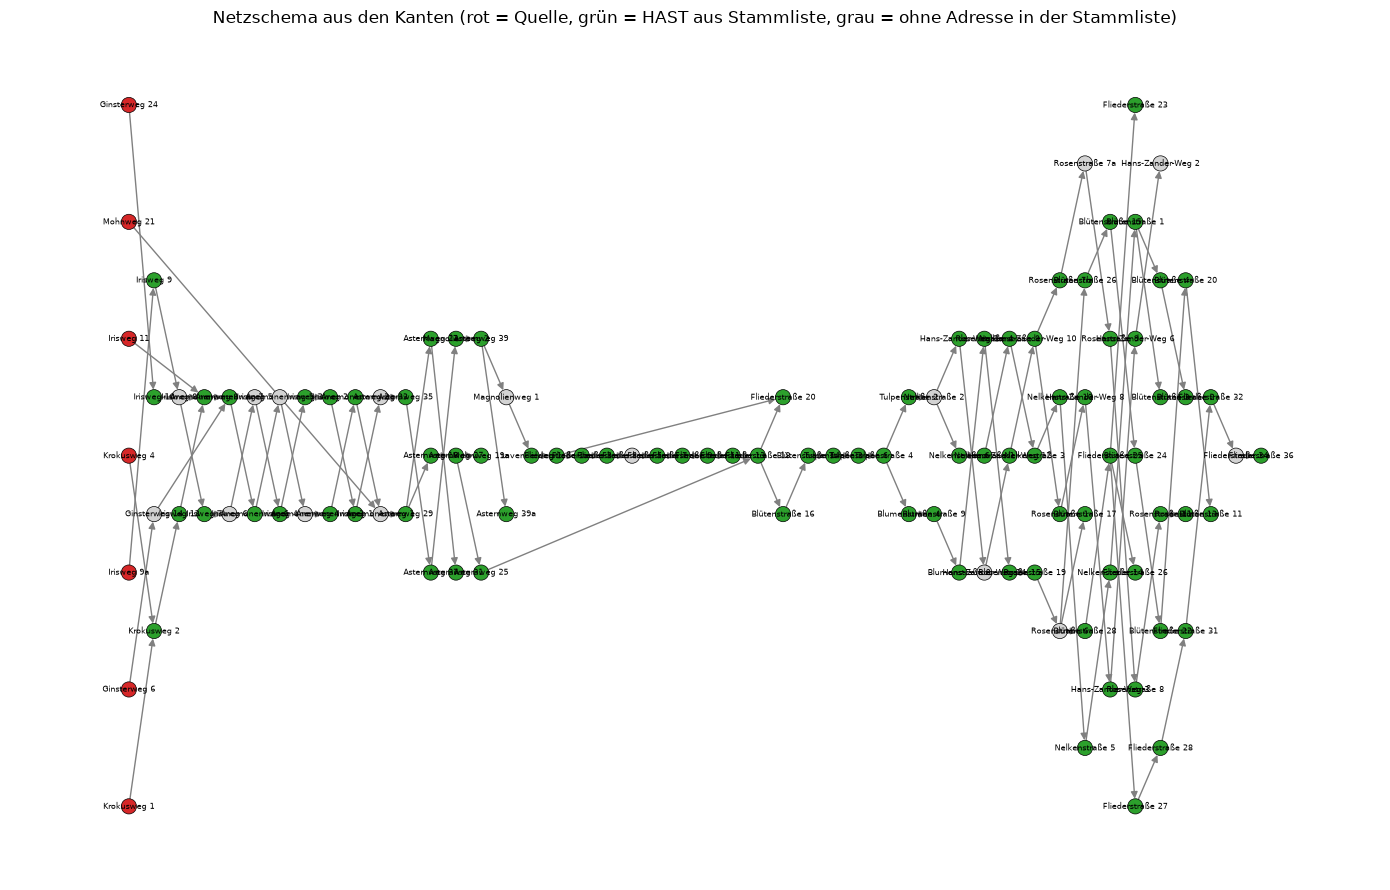

In [20]:
#Schema: Ebene = längster Weg von einer Quelle
if nx.is_directed_acyclic_graph(G):
    for n in G:
        G.nodes[n]["ebene"] = 0
    for n in nx.topological_sort(G):
        for nachfolger in G.successors(n):
            G.nodes[nachfolger]["ebene"] = max(G.nodes[nachfolger]["ebene"], G.nodes[n]["ebene"] + 1)
    layout = nx.multipartite_layout(G, subset_key="ebene", align="vertical")
else:
    layout = nx.spring_layout(G, seed=1, k=0.6)

farbe = ["tab:red" if n in quellen else ("tab:green" if n in stamm_keys else "lightgray") for n in G]
fig, ax = plt.subplots(figsize=(14, 9))
nx.draw_networkx_edges(G, layout, ax=ax, arrows=True, arrowsize=10, edge_color="gray", node_size=120)
nx.draw_networkx_nodes(G, layout, ax=ax, node_color=farbe, node_size=120, edgecolors="black", linewidths=0.5)
nx.draw_networkx_labels(G, layout, ax=ax, labels={n: roh.get(n, n)[:22] for n in G}, font_size=6)
ax.set_title("Netzschema aus den Kanten (rot = Quelle, grün = HAST aus Stammliste, grau = ohne Adresse in der Stammliste)")
ax.axis("off")
plt.tight_layout()
plt.savefig("netzschema.png", dpi=150)
plt.show()

- Ein zusammenhängendes Netz mit 110 Nodes, 110 Kanten und einem Ring.
- Keine Schleifen, keine doppelten Kanten, kein gerichteter Kreis.
- 7 Startknoten ohne Zufluss und 6 Nodes mit mehreren Zuflüssen. Die Kantendatei hat also keinen einzelnen Startpunkt.

## 7 Positionen der Adressen

- Koordinaten aus der Handliste `adressen_koordinaten.ods`, ergänzt durch nachgetragene Listen `fehlende_koordinaten_*.ods` (Spalte `koordinate`, z. B. `49.81, 10.34`).
- Nominatim (Online-Adresssuche) fand meist nur die Straße. Die Suche ist deshalb nur noch optional (`NOMINATIM_SUCHEN`).

In [21]:
NOMINATIM_SUCHEN = False      #True = Adressen neu bei Nominatim suchen (dauert gut 1 s pro Adresse)
ORT, PLZ = "Wiesentheid", "97353"
VORLAGE = next((p for p in [Path("..") / "data" / "manual" / "adressen_koordinaten.ods",
                            Path("..") / "data" / "processed" / "adressen_koordinaten.ods",
                            Path("adressen_koordinaten.ods")] if p.exists()), Path("adressen_koordinaten.ods"))

if NOMINATIM_SUCHEN:
    from geopy.geocoders import Nominatim
    from geopy.extra.rate_limiter import RateLimiter

    geocode = RateLimiter(Nominatim(user_agent="fernwaerme-hast-zuordnung").geocode, min_delay_seconds=1.1)

    def norm_ort(s):
        s = str(s).lower()
        for a, b in UMLAUTE.items():
            s = s.replace(a, b)
        return re.sub(r"[^a-z0-9]+", " ", s).strip()

    def ort_passt(r):
        adr = r.raw.get("address", {})
        gemeinde = [adr.get(k) for k in ("city", "town", "village", "municipality", "suburb", "hamlet")]
        ok_ort = any(g and norm_ort(ORT) in norm_ort(g) for g in gemeinde)
        ok_plz = (not PLZ) or (adr.get("postcode") == PLZ)
        return ok_ort and ok_plz, " / ".join(g for g in gemeinde if g)

    neu = []
    for a in ergebnis["adresse"].dropna().unique():
        strasse, nr = teile_adresse(a)
        anfrage = {"street": f"{nr} {strasse}".strip(), "city": ORT, "country": "Deutschland"}
        if PLZ:
            anfrage["postalcode"] = PLZ
        try:
            r = geocode(anfrage, addressdetails=True)
        except Exception as ex:
            print("Fehler:", type(ex).__name__, ex)
            r = None
        ok, gefundener_ort = ort_passt(r) if r else (False, None)
        neu.append({"adresse": a,
                    "lat": r.latitude if r else None, "lon": r.longitude if r else None,
                    "treffer": r.address if r else None, "ort_gefunden": gefundener_ort, "ort_ok": ok,
                    "genau": ok and bool(r.raw.get("address", {}).get("house_number"))})   #Hausnummer UND richtiger Ort

    nominatim = pd.DataFrame(neu)
    nominatim.to_csv("nominatim_ergebnisse.csv", **CSV)
    print("Genau und im richtigen Ort:", int(nominatim["genau"].sum()))
    print("Treffer im falschen Ort (verworfen):", int((nominatim["lat"].notna() & ~nominatim["ort_ok"]).sum()))
    print("Nur Straße, keine Hausnummer:", int((nominatim["ort_ok"] & ~nominatim["genau"]).sum()))
    print("Nichts gefunden:", int(nominatim["lat"].isna().sum()))

    #Vorlage zum Nachtragen per Hand, nur wenn es noch keine gibt (sonst gingen die Einträge verloren)
    if VORLAGE.exists():
        print(f"{VORLAGE} existiert schon und wird nicht überschrieben.")
    else:
        genau = nominatim[nominatim["genau"]]
        vorlage = (ergebnis[["adresse"]].dropna().drop_duplicates()
                   .merge(genau.assign(koordinate=genau["lat"].round(6).astype(str) + ", " + genau["lon"].round(6).astype(str),
                                       quelle="Nominatim (bitte auf der Karte prüfen)")[["adresse", "koordinate", "quelle"]],
                          on="adresse", how="left")
                   .fillna({"koordinate": "", "quelle": ""})
                   .sort_values("adresse"))
        vorlage.to_excel(VORLAGE, engine="odf", index=False)
        print(len(vorlage), "Adressen nach", VORLAGE, "exportiert")

In [22]:
RAND_GRAD = 0.05      #so weit dürfen Koordinaten außerhalb des KML-Gebiets liegen

dateien = [VORLAGE]      #vorher: [VORLAGE, *sorted(Path(".").glob("fehlende_koordinaten_*.ods"))]
eingabe = pd.concat([pd.read_excel(p, engine="odf", dtype=str).assign(datei=p.name) for p in dateien if p.exists()],
                    ignore_index=True)
eingabe = eingabe[eingabe["koordinate"].fillna("").str.strip() != ""].copy()
eingabe[["lat", "lon"]] = eingabe["koordinate"].apply(lambda s: pd.Series(parse_koordinate(s), dtype=float))

unlesbar = eingabe[eingabe["lat"].isna()]
print("Gelesen:", {p.name: int((eingabe["datei"] == p.name).sum()) for p in dateien if p.exists()})
print("Nicht lesbar:", len(unlesbar))
display(unlesbar[["datei", "adresse", "koordinate"]])

tausch = (eingabe["lat"] < 20) & (eingabe["lon"] > 40)       #Breite und Länge vertauscht
eingabe.loc[tausch, ["lat", "lon"]] = eingabe.loc[tausch, ["lon", "lat"]].values
print("Automatisch getauscht (Breite/Länge vertauscht):", int(tausch.sum()))

b = kml_linien.to_crs(4326).total_bounds
weit = eingabe[(eingabe["lon"] < b[0] - RAND_GRAD) | (eingabe["lon"] > b[2] + RAND_GRAD) |
               (eingabe["lat"] < b[1] - RAND_GRAD) | (eingabe["lat"] > b[3] + RAND_GRAD)]
print("Weit außerhalb des KML-Gebiets (bitte prüfen):", len(weit))
display(weit[["datei", "adresse", "koordinate"]])

eingabe = eingabe.dropna(subset=["lat", "lon"])
cache = eingabe[["adresse", "lat", "lon"]].drop_duplicates("adresse", keep="last").reset_index(drop=True)
cache["key"] = cache["adresse"].apply(norm_adresse)
cache.to_csv("geocode_cache.csv", **CSV)

#Nachgetragene Listen enthalten die Zähler; diese Koordinaten gelten direkt pro Zähler
koord_zaehler = pd.DataFrame(
    [{"z": norm_z(z), "lat": r.lat, "lon": r.lon}
     for r in eingabe.itertuples() if isinstance(getattr(r, "zaehler", None), str)
     for z in r.zaehler.split(",") if norm_z(z)],
    columns=["z", "lat", "lon"]).drop_duplicates("z", keep="last").set_index("z")

print(f"Adressen mit Position: {len(cache)} | Zähler mit eigener Position: {len(koord_zaehler)}")

Gelesen: {'adressen_koordinaten.ods': 101}
Nicht lesbar: 0


,datei,adresse,koordinate


Automatisch getauscht (Breite/Länge vertauscht): 0
Weit außerhalb des KML-Gebiets (bitte prüfen): 0


,datei,adresse,koordinate


Adressen mit Position: 101 | Zähler mit eigener Position: 0


- 101 Adressen gelesen, alle mit Position, keine außerhalb des Netzgebiets.

### 7.1 Adressen den Rohrenden zuordnen

- Jede Adresse bekommt höchstens ein Rohrende, jedes Rohrende höchstens eine Adresse.
- Die nächsten Paare kommen zuerst dran, höchstens bis 40 m Abstand.

In [23]:
MAX_SNAP_M = 40      #bis zu diesem Abstand wird eine Adresse einem Rohrende zugeordnet
UMKREIS_M  = 200     #Leitungen und freie Enden werden nur in diesem Umkreis um die HASTs gezeigt

#Stammliste: alle Adressen mit Zählern (Zähler aus dem letzten Jahr der Adresse)
stamm = ergebnis[["adresse", "änderung"]].copy()
stamm["zaehler_aktuell"] = ergebnis[jahre[::-1]].bfill(axis=1).iloc[:, 0]
stamm["anzahl_zaehler"] = stamm["zaehler_aktuell"].fillna("").apply(lambda s: len([x for x in s.split(", ") if x]))
stamm = stamm.drop_duplicates("adresse").merge(cache[["adresse", "lat", "lon"]], on="adresse", how="left")
ohne_pos = stamm[stamm["lat"].isna()].copy()
mit_pos = stamm[stamm["lat"].notna()].reset_index(drop=True)
g = punkte_gdf(mit_pos).to_crs(hast.crs)

enden = hast.reset_index(drop=True).copy()
enden["eid"] = enden.index
A = np.c_[g.geometry.x, g.geometry.y]
E = np.c_[enden.geometry.x, enden.geometry.y]
D = np.hypot(A[:, [0]] - E[:, 0], A[:, [1]] - E[:, 1])
paare = sorted((D[i, j], i, j) for i, j in zip(*np.where(D <= MAX_SNAP_M)))

used_a, used_e, zuord = set(), set(), {}
for d, i, j in paare:
    if i in used_a or j in used_e:
        continue
    used_a.add(i)
    used_e.add(j)
    zuord[i] = (j, d)

#Ergebnisliste aller Adressen mit Position
rows = []
for i, r in g.iterrows():
    zeile = {"adresse": r["adresse"], "anzahl_zaehler": r["anzahl_zaehler"], "zaehler": r["zaehler_aktuell"],
             "änderung": r["änderung"]}
    if i in zuord:
        j, d = zuord[i]
        ende = enden.iloc[j]
        zeile.update(status="am Rohrende", ende_id=int(ende["eid"]), abstand_m=round(d, 1),
                     rohrart=ende["rohrart"], dn=ende["dn"], geometry=ende.geometry)
    else:
        zeile.update(status=f"kein Rohrende in {MAX_SNAP_M} m (Rohr fehlt?)", ende_id=None, abstand_m=None,
                     rohrart=None, dn=None, geometry=r.geometry)
    rows.append(zeile)
hast_alle = gpd.GeoDataFrame(rows, crs=g.crs)

#Rohrenden ohne Adresse (nur im Umfeld der HAST)
gebiet = hast_alle.geometry.union_all().buffer(UMKREIS_M)
enden_frei = enden[~enden["eid"].isin(used_e) & enden.within(gebiet)].copy()
kml_gebiet = kml[kml.intersects(gebiet)].copy()

print("Adressen insgesamt:", len(stamm))
print("  mit Position:", len(mit_pos), "| ohne Position (fehlen noch in der Tabelle):", len(ohne_pos))
print("  am Rohrende:", int((hast_alle["status"] == "am Rohrende").sum()),
      "| ohne Rohrende in der Nähe:", int((hast_alle["status"] != "am Rohrende").sum()))
print("Rohrenden im Umfeld ohne Adresse:", len(enden_frei))
print("Zähler gesamt (Adressen mit Position):", int(hast_alle["anzahl_zaehler"].sum()))

hast_alle.drop(columns="geometry").assign(rechtswert=hast_alle.geometry.x.round(2),
                                          hochwert=hast_alle.geometry.y.round(2)).to_csv("hast_positionen.csv", **CSV)
ohne_pos[["adresse", "zaehler_aktuell"]].to_csv("hast_ohne_position.csv", **CSV)

#Karte
m = kml_gebiet.to_crs(4326).explore(column="rohrart", categorical=True, name="Leitungen (KML mit Rohrdaten)",
                                    tooltip=["rohrart", "TEXT_LBL", "dn", "mantel", "kml_laenge_m"], style_kwds={"weight": 4})
ns = nur_shp[nur_shp.intersects(gebiet)]
if len(ns):
    ns.to_crs(4326).explore(m=m, color="gray", name="Nur im Shapefile", tooltip=["TEXT_LBL", "laenge_m"],
                            style_kwds={"weight": 2, "dashArray": "6 6"})

fg1 = folium.FeatureGroup(name="HAST (Adresse + Zähler)").add_to(m)
for _, r in hast_alle.to_crs(4326).iterrows():
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=6 + 2 * min(int(r["anzahl_zaehler"]) - 1, 4),
                        color="black", weight=1, fill=True, fill_opacity=0.95,
                        fill_color="green" if r["status"] == "am Rohrende" else "orange",
                        tooltip=f"{r['adresse']} | {r['anzahl_zaehler']} Zähler: {r['zaehler']} | {r['status']}").add_to(fg1)

fg2 = folium.FeatureGroup(name="Rohrenden ohne Adresse").add_to(m)
for _, r in enden_frei.to_crs(4326).iterrows():
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=4, color="dimgray", weight=1, fill=True,
                        fill_color="white", fill_opacity=0.9,
                        tooltip=f"Ende {r['eid']} | {r['rohrart']} | DN {r['dn']}").add_to(fg2)

karte_abschliessen(m, hast_alle.to_crs(4326).total_bounds, "karte_hast.html")

Adressen insgesamt: 100
  mit Position: 100 | ohne Position (fehlen noch in der Tabelle): 0
  am Rohrende: 93 | ohne Rohrende in der Nähe: 7
Rohrenden im Umfeld ohne Adresse: 106
Zähler gesamt (Adressen mit Position): 101


- 93 von 100 Adressen liegen an einem Rohrende, 7 haben keines in der Nähe.
- 106 Rohrenden im Umfeld bleiben ohne Adresse.

## 8 Zähler mit Zeitreihen (Menge X)

- X = Zähler mit Zeitreihe in `data/processed/real_meters`, die auch in der Zuordnung oder in Nodes stehen.
- Gruppe E: Der Zähler hängt an einem Node der Kanten. Gruppe N: ohne Kante.

In [24]:
MODUS = "zuordnung_oder_nodes"      #oder "alle_drei" (Zeitreihe + Zuordnung + nodes)

#Zähler mit Zeitreihen aus den Dateinamen
dateien = [p for p in REAL_METERS.rglob("*") if p.is_file()]
real = pd.DataFrame({"datei": [p.name for p in dateien], "name": [p.stem for p in dateien]})
real["zaehler"] = real["name"].apply(norm_z)
print("Dateien im Ordner:", len(real), "| verschiedene Zähler:", real["zaehler"].nunique())
print("Dateinamen, die keine reine Zahl sind (bitte prüfen):", int((~real["name"].str.fullmatch(r"\d+")).sum()))
display(real[~real["name"].str.fullmatch(r"\d+")].head(15))
print("Zähler mit mehreren Dateien:", int(real["zaehler"].duplicated().sum()))

#Mengen der Quellen
R = set(real["zaehler"]) - {""}
Z = set(lang["zaehler"].apply(norm_z)) - {""}
N = set(nodes["zaehler"].apply(norm_z)) - {""}
regionen = {
    "nur Zeitreihe (weder Zuordnung noch nodes)": R - Z - N,
    "Zeitreihe + Zuordnung, nicht nodes": (R & Z) - N,
    "Zeitreihe + nodes, nicht Zuordnung": (R & N) - Z,
    "Zeitreihe + Zuordnung + nodes": R & Z & N,
    "Zuordnung oder nodes, ohne Zeitreihe": (Z | N) - R,
}
print("\nÜberblick (Zähler):")
display(pd.DataFrame({"anzahl": {k: len(v) for k, v in regionen.items()}}))

X = (R & Z & N) if MODUS == "alle_drei" else (R & (Z | N))
ign = {norm_z(z) for z in IGNORIEREN}
print("Aus X entfernt (IGNORIEREN):", len(X & ign))
X = X - ign
print(f"\nMenge X ({MODUS}): {len(X)} Zähler")

#Adressen je Zähler und Abgleich mit den Kanten
lang2 = lang.assign(z=lang["zaehler"].apply(norm_z))
keys_z = lang2.groupby("z")["adresse_key"].agg(lambda s: set(s.dropna()))
adr_z = lang2.sort_values("jahr").groupby("z")["adresse_roh"].last()

nodes2 = nodes.assign(z=nodes["zaehler"].apply(norm_z), key=nodes["strasse_roh"].apply(norm_adresse))
keys_n = nodes2.groupby("z")["key"].agg(set)
adr_n = nodes2.groupby("z")["strasse_roh"].first()

zeilen = []
for z in sorted(X):
    kz, kn = keys_z.get(z, set()), keys_n.get(z, set())
    an_kante = (kz | kn) & edge_keys
    zeilen.append({"zaehler": z, "adresse": adr_z.get(z) or adr_n.get(z),
                   "in_zuordnung": z in Z, "in_nodes": z in N,
                   "hat_adresse": bool(kz | kn), "hat_edge": bool(an_kante),
                   "edge_node": next(iter(an_kante), None)})
tab = pd.DataFrame(zeilen)
tab["gruppe"] = tab["hat_edge"].map({True: "E (mit Kante)", False: "N (ohne Kante)"})

x_edge, x_ohne = tab[tab["hat_edge"]], tab[~tab["hat_edge"]]
print(f"E (mit Kante): {len(x_edge)} | N (ohne Kante): {len(x_ohne)}")
print("  davon N ohne jede Adresse:", int((~x_ohne["hat_adresse"]).sum()))
print("  Kanten-Nodes, an denen mehrere X-Zähler hängen (Mehrfamilienhäuser):",
      int((x_edge["edge_node"].value_counts() > 1).sum()))
print("\nN (ohne Kante):")
display(x_ohne[["zaehler", "adresse", "hat_adresse", "in_zuordnung", "in_nodes"]])

Dateien im Ordner: 93 | verschiedene Zähler: 93
Dateinamen, die keine reine Zahl sind (bitte prüfen): 0


,datei,name,zaehler


Zähler mit mehreren Dateien: 0

Überblick (Zähler):


,anzahl
nur Zeitreihe (weder Zuordnung noch nodes),4
"Zeitreihe + Zuordnung, nicht nodes",4
"Zeitreihe + nodes, nicht Zuordnung",1
Zeitreihe + Zuordnung + nodes,84
"Zuordnung oder nodes, ohne Zeitreihe",17


Aus X entfernt (IGNORIEREN): 0

Menge X (zuordnung_oder_nodes): 89 Zähler
E (mit Kante): 84 | N (ohne Kante): 5
  davon N ohne jede Adresse: 0
  Kanten-Nodes, an denen mehrere X-Zähler hängen (Mehrfamilienhäuser): 5

N (ohne Kante):


,zaehler,adresse,hat_adresse,in_zuordnung,in_nodes
4,68956342,Irisweg 6 - 8,True,True,True
26,69527345,Fliederstraße 2,True,True,True
36,72135480,Mohnweg 14,True,True,True
79,80912196,Blütenstraße 19,True,True,True
85,80956410,Prichsenstädter Str. 9,True,True,True


- 93 Zähler haben eine Zeitreihe, 89 davon gehören zu X: 84 in Gruppe E, 5 in Gruppe N.
- 4 Zähler haben nur eine Zeitreihe und stehen weder in der Zuordnung noch in Nodes.
- An 5 Kanten-Nodes hängen mehrere Zähler (Mehrfamilienhäuser).

- Koordinaten an die Zähler hängen.
- Fehlen Koordinaten, auch bei Kanten-Nodes ohne Zähler, wird die Liste `fehlende_koordinaten_<Zeit>.ods` zum Nachtragen geschrieben.
- Nach dem Ausfüllen Abschnitt 7 erneut ausführen.

In [25]:
#Schlüssel pro Zähler: Node aus den Kanten, sonst die bereinigte Adresse
tab["key"] = [n if isinstance(n, str) else adress_key(a) for n, a in zip(tab["edge_node"], tab["adresse"])]
tab = tab.merge(cache.drop_duplicates("key")[["key", "lat", "lon"]], on="key", how="left")
for sp in ("lat", "lon"):
    tab[sp] = tab[sp].fillna(tab["zaehler"].map(koord_zaehler[sp]))
tab["hat_koord"] = tab["lat"].notna()

print("Zähler in X:", len(tab), "| mit Koordinate:", int(tab["hat_koord"].sum()))
print(tab.groupby("gruppe")["hat_koord"].agg(gesamt="size", mit_koordinate="sum"))
print("Verschiedene Adressen in E:", tab.loc[tab["hat_edge"], "key"].nunique(),
      "| davon mit Koordinate:", tab.loc[tab["hat_edge"] & tab["hat_koord"], "key"].nunique())

#Fehlende Positionen: Zähler aus X und Kanten-Nodes ohne Zähler (z.B. Häuser, über die die Leitung weiterläuft)
fehlt = tab[~tab["hat_koord"]]
bekannt = set(cache["key"]) | set(tab.loc[tab["hat_koord"], "key"])
nodes_ohne_pos = sorted(n for n in G if n not in bekannt and n not in set(fehlt["key"]))
print("Kanten-Nodes ohne Position:", len(nodes_ohne_pos))

if len(fehlt) or nodes_ohne_pos:
    liste = pd.concat([
        fehlt.groupby("key").agg(adresse=("adresse", "first"), zaehler=("zaehler", ", ".join), gruppe=("gruppe", "first")),
        pd.DataFrame({"adresse": [roh.get(n, n) for n in nodes_ohne_pos], "zaehler": "",
                      "gruppe": "Kanten-Node ohne Zähler"}, index=nodes_ohne_pos),
    ]).reset_index(drop=True).sort_values(["gruppe", "adresse"]).assign(koordinate="")
    dateiname = f"fehlende_koordinaten_{datetime.now():%Y%m%d_%H%M}.ods"
    liste.to_excel(dateiname, engine="odf", index=False)
    print("Geschrieben:", dateiname, "|", len(liste), "Adressen ohne Koordinate")
    display(liste.head(20))

tab.to_csv("x_zaehler_mit_gruppe.csv", **CSV)

Zähler in X: 89 | mit Koordinate: 89
                gesamt  mit_koordinate
gruppe                                
E (mit Kante)       84              84
N (ohne Kante)       5               5
Verschiedene Adressen in E: 79 | davon mit Koordinate: 79
Kanten-Nodes ohne Position: 17
Geschrieben: fehlende_koordinaten_20261117_2243.ods | 17 Adressen ohne Koordinate


,adresse,zaehler,gruppe,koordinate
0,Anemonenweg 1,,Kanten-Node ohne Zähler,
1,Anemonenweg 4,,Kanten-Node ohne Zähler,
2,Anemonenweg 5,,Kanten-Node ohne Zähler,
3,Asternweg 33,,Kanten-Node ohne Zähler,
4,Fliederstraße 34,,Kanten-Node ohne Zähler,
5,Fliederstraße 5,,Kanten-Node ohne Zähler,
6,Ginsterweg 14,,Kanten-Node ohne Zähler,
7,Ginsterweg 6,,Kanten-Node ohne Zähler,
8,Hans-Zander-Weg 14,,Kanten-Node ohne Zähler,
9,Hans-Zander-Weg 2,,Kanten-Node ohne Zähler,


In [26]:
x_edge = tab[tab["hat_edge"]].copy()
print(f"E (mit Kante): {len(x_edge)} Zähler | mit Koordinate: {int(x_edge['hat_koord'].sum())} | ohne: {int((~x_edge['hat_koord']).sum())}")
display(x_edge[~x_edge["hat_koord"]][["zaehler", "adresse", "edge_node"]])

knoten = (x_edge.dropna(subset=["lat", "lon"]).groupby("edge_node")
                .agg(lat=("lat", "mean"), lon=("lon", "mean"), lat_n=("lat", "nunique"),
                     zaehler=("zaehler", ", ".join), anzahl=("zaehler", "nunique"),
                     adresse=("adresse", "first")).reset_index())
print("Nodes mit Zählern aus E:", len(knoten), "| Nodes mit abweichenden Koordinaten pro Zähler:", int((knoten["lat_n"] > 1).sum()))

#Positionen aller Nodes: E-Nodes aus den Zählern, die übrigen aus der Adressliste
cpos = cache.drop_duplicates("key").set_index("key")
koord = {r.edge_node: (r.lat, r.lon) for r in knoten.itertuples()}
for n in G:
    if n not in koord and n in cpos.index:
        koord[n] = (cpos.loc[n, "lat"], cpos.loc[n, "lon"])
e_nodes = set(knoten["edge_node"])

zeichnen = [(v, n) for v, n in G.edges if v in koord and n in koord]
print(f"\nKanten gesamt: {G.number_of_edges()} | mit Position an beiden Enden: {len(zeichnen)} | "
      f"berühren einen E-Node: {sum(1 for v, n in G.edges if v in e_nodes or n in e_nodes)}")
ohne_koord = sorted(set(G) - set(koord))
print("Nodes in den Kanten ohne Position:", len(ohne_koord))
display(pd.DataFrame({"node": [roh.get(n, n) for n in ohne_koord]}))

#Karte
m = folium.Map(location=[knoten["lat"].mean(), knoten["lon"].mean()], zoom_start=17, tiles="OpenStreetMap")
fk = folium.FeatureGroup(name="Kanten (von → nach, Luftlinie)").add_to(m)
for v, n in zeichnen:
    linie = folium.PolyLine([koord[v], koord[n]], color="#d6402d", weight=3, opacity=0.8,
                            tooltip=f"{roh.get(v, v)} → {roh.get(n, n)}").add_to(fk)
    PolyLineTextPath(linie, "     ►     ", repeat=True, offset=7,
                     attributes={"fill": "#d6402d", "font-size": "14"}).add_to(fk)

fn = folium.FeatureGroup(name=f"Zähler aus E ({len(x_edge)})").add_to(m)
for r in knoten.itertuples():
    folium.CircleMarker([r.lat, r.lon], radius=6 + 2 * min(r.anzahl - 1, 4), color="black", weight=1,
                        fill=True, fill_color="green", fill_opacity=0.95,
                        tooltip=f"{r.adresse} | {r.anzahl} Zähler: {r.zaehler}").add_to(fn)

fo = folium.FeatureGroup(name="Andere Nodes mit Position").add_to(m)
for n, (la, lo) in koord.items():
    if n not in e_nodes:
        folium.CircleMarker([la, lo], radius=4, color="dimgray", weight=1, fill=True, fill_color="lightgray",
                            fill_opacity=0.9, tooltip=roh.get(n, n)).add_to(fo)

la, lo = zip(*koord.values())
karte_abschliessen(m, [min(lo), min(la), max(lo), max(la)], "karte_kanten_E.html")
display(m)

#Export der E-Zähler mit UTM-Koordinaten (passend zu Shapefile und KML)
x_pos = punkte_gdf(x_edge.dropna(subset=["lat", "lon"])).to_crs(CRS_UTM)
x_pos.drop(columns="geometry").assign(rechtswert=x_pos.geometry.x.round(2),
                                      hochwert=x_pos.geometry.y.round(2)).to_csv("x83_mit_koordinaten.csv", **CSV)

E (mit Kante): 84 Zähler | mit Koordinate: 84 | ohne: 0


,zaehler,adresse,edge_node


Nodes mit Zählern aus E: 79 | Nodes mit abweichenden Koordinaten pro Zähler: 0

Kanten gesamt: 110 | mit Position an beiden Enden: 77 | berühren einen E-Node: 102
Nodes in den Kanten ohne Position: 17


,node
0,Anemonenweg 1
1,Anemonenweg 4
2,Anemonenweg 5
3,Asternweg 33
4,Fliederstraße 34
5,Fliederstraße 5
6,Ginsterweg 14
7,Ginsterweg 6
8,Hans-Zander-Weg 14
9,Hans-Zander-Weg 2


- Alle 89 Zähler in X haben eine Koordinate.
- 17 Kanten-Nodes ohne Zähler haben keine Position. Deshalb haben nur 77 von 110 Kanten an beiden Enden eine Position.

## 9 Kanten über die Rohre legen

- Jede Kante wird auf dem kürzesten Weg durch das KML-Leitungsnetz gezeichnet statt als Luftlinie.
- Die Leitungen werden an Kreuzungen geteilt. Offene Leitungsenden rasten auf das nächste Rohr ein: bis `SNAP_M` gelten sie als verbunden, bis `MAX_LUECKE_M` wird die Lücke überbrückt, zählt beim Routing aber teurer und wird ausgewiesen.
- Start und Ziel einer Kante: das zugeordnete Rohrende der Station (Abschnitt 7.1), sonst die Adresskoordinate, eingerastet auf das nächste Rohr.

In [27]:
SNAP_M          = 1.0    #Lücken bis zu dieser Länge gelten als verbunden (Zeichenungenauigkeit)
MAX_LUECKE_M    = 25     #größere Lücken werden bis zu dieser Länge überbrückt, aber als Lücke markiert
LUECKE_FAKTOR   = 5      #eine überbrückte Lücke zählt beim Routing so viel mal teurer als ein echtes Rohr
MAX_ANBINDUNG_M = 50     #so weit darf eine Node-Position höchstens vom Netz entfernt sein

def pkt(c):
    return (round(c[0], 3), round(c[1], 3))

#Leitungen an allen Kreuzungen teilen, Teilnetze bestimmen
segs = [s for s in unary_union(list(kml.geometry[kml.geom_type == "LineString"])).geoms if s.length > 0]
seg_baum = shapely.STRtree(segs)

roh_netz = nx.Graph((pkt(s.coords[0]), pkt(s.coords[-1])) for s in segs)
komp = {n: k for k, c in enumerate(nx.connected_components(roh_netz)) for n in c}
seg_komp = [komp[pkt(s.coords[0])] for s in segs]

#Verbinder sammeln: (Punkt, Segment, Stelle entlang des Segments, Typ, Länge)
verbinder = []
for p in (n for n in roh_netz if roh_netz.degree(n) == 1):          #offene Enden
    pt = Point(p)
    kand = [(segs[j].distance(pt), j) for j in seg_baum.query(pt, predicate="dwithin", distance=MAX_LUECKE_M)
            if seg_komp[j] != komp[p]]
    if kand:
        d, j = min(kand)
        verbinder.append((p, j, segs[j].project(pt), "Verbindung" if d <= SNAP_M else "Lücke", d))

hast_rohrende = {norm_adresse(r.adresse): r.geometry for r in hast_alle.itertuples() if r.status == "am Rohrende"}
koord_utm = gpd.GeoSeries([Point(lo, la) for la, lo in koord.values()], index=list(koord), crs=4326).to_crs(CRS_UTM)

anker = {}                                                           #Kanten-Node -> Punkt im Netz
for n in G:
    q = hast_rohrende.get(n, koord_utm.get(n))
    if q is None:
        continue
    j = seg_baum.query_nearest(q)[0]
    if segs[j].distance(q) <= MAX_ANBINDUNG_M:
        anker[n] = pkt(q.coords[0])
        verbinder.append((anker[n], j, segs[j].project(q), "Anbindung", segs[j].distance(q)))

#Routing-Graph: Rohrstücke plus Verbinder
teilungen = {}
for _, j, stelle, _, _ in verbinder:
    teilungen.setdefault(j, set()).add(stelle)

netz = nx.Graph()
for i, s in enumerate(segs):
    ds = sorted(d for d in teilungen.get(i, ()) if 0 < d < s.length)
    stellen = [0.0, *ds, s.length]
    punkte = [pkt(s.coords[0]), *[pkt(s.interpolate(d).coords[0]) for d in ds], pkt(s.coords[-1])]
    for a, b, pa, pb in zip(stellen, stellen[1:], punkte, punkte[1:]):
        if pa != pb:
            netz.add_edge(pa, pb, w=b - a, typ="Rohr", geom=substring(s, a, b))
for p, j, stelle, typ, d in verbinder:
    ziel = pkt(segs[j].interpolate(stelle).coords[0])
    if p != ziel:
        netz.add_edge(p, ziel, w=d * (LUECKE_FAKTOR if typ == "Lücke" else 1), typ=typ, geom=LineString([p, ziel]))

def route(a, b):
    pfad = nx.shortest_path(netz, a, b, weight="w")
    coords, luecke = [], 0.0
    for u, v in zip(pfad, pfad[1:]):
        dat = netz.edges[u, v]
        c = list(dat["geom"].coords)
        if pkt(c[0]) != u:
            c = c[::-1]
        coords += c if not coords else c[1:]
        if dat["typ"] == "Lücke":
            luecke += dat["geom"].length
    return LineString(coords), luecke

zeilen = []
for v, n in G.edges:
    zeile = {"von": roh.get(v, v), "nach": roh.get(n, n)}
    if v in anker and n in anker:
        luft = Point(anker[v]).distance(Point(anker[n]))
        try:
            geom, luecke = route(anker[v], anker[n])
            zeile.update(status="über Rohre" if luecke == 0 else "über Rohre mit Lücke", laenge_rohr_m=round(geom.length, 1),
                         luftlinie_m=round(luft, 1), luecke_m=round(luecke, 1), geometry=geom)
        except nx.NetworkXNoPath:
            zeile.update(status="kein Weg im Netz (Luftlinie)", luftlinie_m=round(luft, 1),
                         geometry=LineString([anker[v], anker[n]]))
    else:
        zeile.update(status="Node ohne Position", geometry=None)
    zeilen.append(zeile)
kanten_rohr = gpd.GeoDataFrame(zeilen, geometry="geometry", crs=CRS_UTM)
kanten_rohr["umweg"] = (kanten_rohr["laenge_rohr_m"] / kanten_rohr["luftlinie_m"]).round(1)

print("Rohrstücke:", len(segs), "| Teilnetze vor dem Einrasten:", len(set(komp.values())))
print("Offene Enden eingerastet:", sum(t != "Anbindung" for *_, t, _ in verbinder),
      "| davon als Lücke überbrückt:", sum(t == "Lücke" for *_, t, _ in verbinder))
print("Kanten-Nodes im Netz verankert:", len(anker), "von", G.number_of_nodes())
print(kanten_rohr["status"].value_counts().to_dict())
print("Umweg (Rohrlänge / Luftlinie):", kanten_rohr["umweg"].describe().round(1).to_dict())

print("\nGrößte Umwege (bitte auf der Karte prüfen):")
display(kanten_rohr.drop(columns="geometry").sort_values("umweg", ascending=False).head(10))
print("Kanten mit überbrückter Lücke oder ohne Weg:")
display(kanten_rohr[~kanten_rohr["status"].isin(["über Rohre", "Node ohne Position"])].drop(columns="geometry"))

kanten_rohr.drop(columns="geometry").to_csv("kanten_auf_rohren.csv", **CSV)
kanten_rohr.dropna(subset=["geometry"]).to_crs(4326).to_file("kanten_auf_rohren.geojson", driver="GeoJSON")

Rohrstücke: 2345 | Teilnetze vor dem Einrasten: 272
Offene Enden eingerastet: 700 | davon als Lücke überbrückt: 663
Kanten-Nodes im Netz verankert: 93 von 110
{'über Rohre': 71, 'Node ohne Position': 33, 'über Rohre mit Lücke': 6}
Umweg (Rohrlänge / Luftlinie): {'count': 77.0, 'mean': 1.7, 'std': 0.5, 'min': 1.1, '25%': 1.3, '50%': 1.5, '75%': 1.8, 'max': 3.4}

Größte Umwege (bitte auf der Karte prüfen):


,von,nach,status,laenge_rohr_m,luftlinie_m,luecke_m,umweg
27,Irisweg 9a,Irisweg 9,über Rohre,60.1,17.6,0.0,3.4
109,Rosenstraße 11,Rosenstraße 13,über Rohre,57.8,19.1,0.0,3.0
62,Blumenstraße 8,Rosenstraße 4,über Rohre,83.6,27.7,0.0,3.0
1,Krokusweg 2,Irisweg 13,über Rohre mit Lücke,53.9,18.3,7.9,2.9
41,Asternweg 39,Asternweg 39a,über Rohre,57.5,19.9,0.0,2.9
5,Ginsterweg 24,Irisweg 10,über Rohre,136.7,53.6,0.0,2.6
6,Irisweg 10,Anemonenweg 8,über Rohre,59.3,22.4,0.0,2.6
77,Fliederstraße 25,Fliederstraße 26,über Rohre,81.0,33.8,0.0,2.4
14,Anemonenweg 3,Anemonenweg 2,über Rohre,27.6,11.5,0.0,2.4
93,Blütenstraße 1,Blütenstraße 3,über Rohre,41.1,18.1,0.0,2.3


Kanten mit überbrückter Lücke oder ohne Weg:


,von,nach,status,laenge_rohr_m,luftlinie_m,luecke_m,umweg
0,Krokusweg 4,Krokusweg 2,über Rohre mit Lücke,54.4,31.7,13.4,1.7
1,Krokusweg 2,Irisweg 13,über Rohre mit Lücke,53.9,18.3,7.9,2.9
34,Irisweg 3,Irisweg 2,über Rohre mit Lücke,94.9,47.2,12.1,2.0
35,Irisweg 2,Irisweg 1,über Rohre mit Lücke,80.4,42.3,12.1,1.9
45,Fliederstraße 1a,Fliederstraße 20,über Rohre mit Lücke,244.0,226.1,18.4,1.1
52,Fliederstraße 11,Fliederstraße 13,über Rohre mit Lücke,31.4,23.1,18.4,1.4


In [28]:
FARBE = {"über Rohre": "#d6402d", "über Rohre mit Lücke": "#e68a00", "kein Weg im Netz (Luftlinie)": "gray"}

gezeichnet = kanten_rohr.dropna(subset=["geometry"]).to_crs(4326)
gebiet_k = kanten_rohr.dropna(subset=["geometry"]).union_all().buffer(UMKREIS_M)

m = folium.Map(tiles="OpenStreetMap")
kml[kml.intersects(gebiet_k)].to_crs(4326).explore(
    m=m, color="steelblue", name="Leitungen (KML)", tooltip=["rohrart", "TEXT_LBL", "dn"],
    style_kwds={"weight": 2, "opacity": 0.5})

fk = folium.FeatureGroup(name="Kanten über die Rohre (von → nach)").add_to(m)
for r in gezeichnet.itertuples():
    farbe = FARBE[r.status]
    linie = folium.PolyLine([(y, x) for x, y in r.geometry.coords], color=farbe, weight=3, opacity=0.85,
                            dash_array="6 6" if r.status.startswith("kein") else None,
                            tooltip=f"{r.von} → {r.nach} | {r.status} | {r.laenge_rohr_m} m Rohr, "
                                    f"{r.luftlinie_m} m Luftlinie, Lücke {r.luecke_m} m").add_to(fk)
    PolyLineTextPath(linie, "     ►     ", repeat=True, offset=7, attributes={"fill": farbe, "font-size": "14"}).add_to(fk)

fn = folium.FeatureGroup(name="Kanten-Nodes").add_to(m)
anker_wgs = gpd.GeoSeries([Point(p) for p in anker.values()], index=list(anker), crs=CRS_UTM).to_crs(4326)
for n, p in anker_wgs.items():
    folium.CircleMarker([p.y, p.x], radius=5, color="black", weight=1, fill=True, fill_opacity=0.95,
                        fill_color="red" if n in quellen else ("green" if n in e_nodes else "lightgray"),
                        tooltip=roh.get(n, n)).add_to(fn)

karte_abschliessen(m, gezeichnet.total_bounds, "karte_kanten_rohre.html")

- 71 Kanten laufen über Rohre, 6 weitere nur mit überbrückter Lücke, 33 haben einen Node ohne Position.
- Der Rohrweg ist im Median 1,5-mal so lang wie die Luftlinie, höchstens 3,4-mal.
- Große Umwege sollte man auf der Karte prüfen.

## 10 Zeitreihen der Zähler in Gruppe E

- Die Stundenwerte der 84 Zähler in Gruppe E einlesen (CSV aus Notebook 00).
- Spalten erkennen, unplausible Temperaturen (außerhalb 0 bis 130 °C) als Messfehler ausblenden, Tageswerte bilden.
- Datenqualität prüfen: Lücken, Stunden ohne Durchfluss, negative Spreizung (Spreizung = Vorlauf minus Rücklauf).

In [29]:


ORDNER = REAL_METERS      #Ausgabe von Notebook 00

FLUSS_MIN_LH    = 10      #Stunden bis zu diesem Durchfluss (l/h) ausblenden, Startwert
GEWICHTET       = True    #Tageswert nach Durchfluss gewichtet (sonst Median)
MIN_STUNDEN_TAG = 6       #so viele gültige Stunden braucht ein Tag für einen Tageswert
T_MIN, T_MAX    = 0, 130  #Temperaturen außerhalb gelten als Messfehler
OVERRIDE        = {}      #nur falls eine Spalte nicht erkannt wird, z.B. {"vor": "Flow temperature (°C)"}

MUSTER = {
    "zeit":     r"^\s*(timestamp|zeit|time|datum|date)",
    "vor":      r"^\s*flow\s*temp",
    "rueck":    r"^\s*return\s*temp",
    "diff":     r"temperature\s*diff",
    "fluss":    r"volume\s*flow",
    "leistung": r"^\s*power",
    "energie":  r"^\s*energy",
}

if "norm_z" not in globals():
    def norm_z(s): return re.sub(r"\D", "", str(s)).lstrip("0")

zaehler_liste = sorted(set(x_edge["zaehler"].apply(norm_z)))
pfade = {norm_z(p.stem): p for p in Path(ORDNER).rglob("*.csv")}
ohne_csv = [z for z in zaehler_liste if z not in pfade]
print(f"Zähler in E: {len(zaehler_liste)} | CSV gefunden: {len(zaehler_liste) - len(ohne_csv)} | ohne CSV: {len(ohne_csv)}")
if ohne_csv:
    print("Ohne CSV:", ohne_csv)

def num(s):
    return pd.to_numeric(s.astype(str).str.strip().str.replace(",", ".", regex=False), errors="coerce")

def lies_csv(pfad):
    roh = Path(pfad).read_bytes()
    text = None
    for enc in ("utf-8-sig", "cp1252"):
        try:
            text = roh.decode(enc); break
        except UnicodeDecodeError:
            pass
    if text is None:
        text = roh.decode("latin-1")
    kopf_z = text.splitlines()[:15]
    sep = max([";", ",", "\t", "|"], key=lambda s: sum(z.count(s) for z in kopf_z))
    maxn = max(z.count(sep) for z in kopf_z)
    kopf = next(i for i, z in enumerate(kopf_z) if z.count(sep) == maxn)
    return pd.read_csv(StringIO(text), sep=sep, skiprows=kopf, dtype=str), sep

def zeit_parse(s):
    s = s.astype(str).str.strip()
    if s.str.fullmatch(r"\d{10}|\d{13}").mean() > 0.9:
        t = pd.to_datetime(pd.to_numeric(s, errors="coerce"), unit="ms" if s.str.len().iloc[0] == 13 else "s", errors="coerce")
    elif s.str.contains(r"(?:Z|[+-]\d{2}:?\d{2})$").mean() > 0.5:      #mit Zeitzone
        t = pd.to_datetime(s, errors="coerce", utc=True).dt.tz_convert("Europe/Berlin").dt.tz_localize(None)
    elif s.str.match(r"\d{4}-\d{2}-\d{2}").mean() > 0.9:      #Jahr vorne (Notebook 00), dayfirst würde Tag und Monat bis zum 12. tauschen
        t = pd.to_datetime(s, errors="coerce", format="ISO8601")
    else:
        t = pd.to_datetime(s, dayfirst=True, errors="coerce", format="mixed")
    return t

def spalte(cols, muster):
    for c in cols:
        if re.search(muster, str(c), re.I):
            return c
    return None

serien, tage, info = {}, {}, []
for z in zaehler_liste:
    if z not in pfade:
        continue
    try:
        df, sep = lies_csv(pfade[z])
        cols = list(df.columns)
        sp = {k: OVERRIDE.get(k) or spalte(cols, m) for k, m in MUSTER.items()}
        if None in (sp["zeit"], sp["vor"], sp["rueck"]) or sp["vor"] == sp["rueck"]:
            info.append({"zaehler": z, "status": "Spalten nicht erkannt", "spalten": cols})
            continue

        d = pd.DataFrame({"vor": num(df[sp["vor"]]).values, "rueck": num(df[sp["rueck"]]).values},
                         index=pd.DatetimeIndex(zeit_parse(df[sp["zeit"]])))
        for k in ("fluss", "leistung", "diff", "energie"):
            d[k] = num(df[sp[k]]).values if sp[k] else np.nan
        d = d[d.index.notna()].sort_index()
        d = d[~d.index.duplicated(keep="first")]
        d = d.resample("1h").mean()                       #lückenloses Stundenraster, fehlende Stunden = NaN

        #Messfehler entfernen, Spreizung berechnen, Stunden ohne Durchfluss ausblenden
        schlecht_t = (d["vor"].lt(T_MIN) | d["vor"].gt(T_MAX) | d["rueck"].lt(T_MIN) | d["rueck"].gt(T_MAX))
        d.loc[schlecht_t, ["vor", "rueck"]] = np.nan
        d["spreizung"] = d["vor"] - d["rueck"]
        ohne_fluss = d["fluss"].le(FLUSS_MIN_LH) if sp["fluss"] else pd.Series(False, index=d.index)
        d.loc[ohne_fluss, "spreizung"] = np.nan

        #Gegenproben
        luecke = d["vor"].isna() | d["rueck"].isna()
        runs = luecke.ne(luecke.shift()).cumsum()
        laengste = int(luecke.groupby(runs).sum().max())
        abw_geraet = (d["vor"] - d["rueck"] - d["diff"]).abs().median() if sp["diff"] else np.nan
        ok = d["spreizung"].gt(1) & d["fluss"].gt(FLUSS_MIN_LH)
        pv = (d.loc[ok, "leistung"] / (d.loc[ok, "fluss"] * d.loc[ok, "spreizung"] * 0.001163)).median() \
             if (sp["leistung"] and sp["fluss"] and ok.any()) else np.nan

        #Tageswert
        gueltig = d["spreizung"].notna()
        median_t = d["spreizung"].resample("D").median()
        if GEWICHTET and sp["fluss"]:
            w = d["fluss"].where(gueltig)
            t_ = (d["spreizung"] * w).resample("D").sum(min_count=1) / w.resample("D").sum(min_count=1)
            t_ = t_.fillna(median_t)
        else:
            t_ = median_t
        tage[z] = t_.where(gueltig.resample("D").sum() >= MIN_STUNDEN_TAG)
        serien[z] = d

        sp_ok = d["spreizung"].dropna()
        info.append({"zaehler": z, "status": "ok", "von": d.index.min().date(), "bis": d.index.max().date(),
                     "stunden": len(d), "anteil_vorhanden": round(1 - luecke.mean(), 2),
                     "laengste_luecke_h": laengste,
                     "anteil_ohne_fluss": round(ohne_fluss.mean(), 2),
                     "anteil_negativ": round((sp_ok < 0).mean(), 3) if len(sp_ok) else np.nan,
                     "vor_median": round(d["vor"].median(), 1), "rueck_median": round(d["rueck"].median(), 1),
                     "abw_zu_geraet_K": round(abw_geraet, 2) if pd.notna(abw_geraet) else np.nan,
                     "leistung_passt": round(pv, 2) if pd.notna(pv) else np.nan,
                     "trenner": repr(sep),
                     "spalten": " | ".join(str(sp[k]) for k in ("zeit", "vor", "rueck", "fluss", "leistung"))})
    except Exception as ex:
        info.append({"zaehler": z, "status": f"Fehler: {type(ex).__name__}: {ex}"})

ueberblick = pd.DataFrame(info)
tag = pd.DataFrame(tage)

print("\nStatus:", ueberblick["status"].value_counts().to_dict())
if "spalten" in ueberblick:
    print("\nErkannte Spalten (zeit | vor | rueck | fluss | leistung):")
    print(ueberblick["spalten"].astype(str).value_counts().head(5).to_string())
display(ueberblick[ueberblick["status"] != "ok"])

ok_t = ueberblick[ueberblick["status"] == "ok"]
if len(ok_t):
    print(f"\nZeitraum: {ok_t['von'].min()} bis {ok_t['bis'].max()} | Tageswerte: {tag.shape[0]} Tage x {tag.shape[1]} Zähler")
    print("Anteil vorhandener Stunden (Median über alle Zähler):", round(ok_t["anteil_vorhanden"].median(), 2))
    print("Anteil ohne Durchfluss (Median):", round(ok_t["anteil_ohne_fluss"].median(), 2))
    print("Zähler mit weniger als 80 % vorhandenen Stunden:", int((ok_t["anteil_vorhanden"] < 0.8).sum()))
    print("Zähler mit mehr als 10 % negativer Spreizung:", int((ok_t["anteil_negativ"] > 0.1).sum()))
    print("Zähler, bei denen die eigene Spreizung um mehr als 0,5 K vom Zählerwert abweicht:", int((ok_t["abw_zu_geraet_K"] > 0.5).sum()))
    print("Zähler, bei denen Leistung nicht zu Durchfluss und Spreizung passt (Verhältnis außerhalb 0,8 bis 1,2):",
          int(((ok_t["leistung_passt"] < 0.8) | (ok_t["leistung_passt"] > 1.2)).sum()))
    display(ok_t.drop(columns=["spalten", "trenner"]).head(12))
    auffaellig = ok_t[(ok_t["anteil_negativ"] > 0.1) | (ok_t["abw_zu_geraet_K"] > 0.5)
                      | (ok_t["leistung_passt"] < 0.8) | (ok_t["leistung_passt"] > 1.2)]
    print("\nAuffällige Zähler:")
    display(auffaellig[["zaehler", "anteil_negativ", "abw_zu_geraet_K", "leistung_passt", "vor_median", "rueck_median"]])

Zähler in E: 84 | CSV gefunden: 84 | ohne CSV: 0



Status: {'ok': 84}

Erkannte Spalten (zeit | vor | rueck | fluss | leistung):
spalten
Timestamp | Flow temperature (°C) | Return temperature (°C) | Volume flow (l/h) | Power (kW)    84


,zaehler,status,von,bis,stunden,anteil_vorhanden,laengste_luecke_h,anteil_ohne_fluss,anteil_negativ,vor_median,rueck_median,abw_zu_geraet_K,leistung_passt,trenner,spalten



Zeitraum: 2021-11-01 bis 2026-07-20 | Tageswerte: 1723 Tage x 84 Zähler
Anteil vorhandener Stunden (Median über alle Zähler): 0.84
Anteil ohne Durchfluss (Median): 0.29
Zähler mit weniger als 80 % vorhandenen Stunden: 40
Zähler mit mehr als 10 % negativer Spreizung: 1
Zähler, bei denen die eigene Spreizung um mehr als 0,5 K vom Zählerwert abweicht: 0
Zähler, bei denen Leistung nicht zu Durchfluss und Spreizung passt (Verhältnis außerhalb 0,8 bis 1,2): 0


,zaehler,status,von,bis,stunden,anteil_vorhanden,laengste_luecke_h,anteil_ohne_fluss,anteil_negativ,vor_median,rueck_median,abw_zu_geraet_K,leistung_passt
0,53198226,ok,2021-11-01,2025-07-11,32342,0.69,1487,0.25,0.000,73.1,51.5,0.0,0.99
1,65273846,ok,2021-11-01,2025-05-05,30732,0.72,23,0.48,0.009,37.2,25.9,0.0,0.99
2,66761022,ok,2021-11-01,2024-05-13,22170,0.61,24,0.00,0.005,77.0,65.0,0.3,0.98
3,68956339,ok,2021-11-01,2025-07-11,32342,0.71,244,0.20,0.004,72.2,49.8,0.0,0.99
4,68956344,ok,2021-11-01,2025-07-11,32342,0.73,23,0.40,0.009,65.9,51.2,0.0,0.99
5,68956345,ok,2021-11-01,2025-07-11,32342,0.73,23,0.29,0.001,73.8,45.5,0.0,0.99
6,68956347,ok,2021-11-01,2026-07-20,41317,0.79,23,0.41,0.003,71.4,35.2,0.0,0.99
7,68956348,ok,2021-11-01,2025-07-11,32342,0.46,15409,0.41,0.005,53.0,40.1,0.0,0.99
8,68956351,ok,2021-11-01,2025-07-11,32342,0.73,24,0.12,0.024,74.9,72.1,0.0,0.98
9,68956352,ok,2021-11-01,2025-07-11,32342,0.73,23,0.17,0.005,66.6,58.6,0.0,0.98



Auffällige Zähler:


,zaehler,anteil_negativ,abw_zu_geraet_K,leistung_passt,vor_median,rueck_median
66,80912182,0.146,0.0,0.98,75.2,73.9


- Für alle 84 Zähler gibt es eine CSV, alle Spalten wurden erkannt.
- Zeitraum 1.11.2021 bis 20.7.2026, also 1723 Tage.

,zaehler,anteil_negativ,vor_median,rueck_median,adresse
66,80912182,0.146,75.2,73.9,Fliederstraße 27


Zähler ohne Wert bei 'leistung_passt' oder 'abw_zu_geraet_K' (dort lief die Prüfung leer): 0 / 0



Anteil aller Stunden (Median über die 84 Zähler), in Prozent:
keine Messzeile                9.6
Zeile da, Temperatur fehlt     0.0
kein Durchfluss (≤ 10 l/h)    29.1
nutzbar                       59.4

Lücken ohne Messzeile nach Länge:


,anzahl,anteil_der_fehlenden_stunden_%
≤ 3 h,896,0.0
4–24 h,13279,82.0
1–7 Tage,10,0.0
> 7 Tage,16,18.0



Durchfluss in l/h, Quantile 10/25/50/75/90 %: [0.0, 0.0, 50.0, 175.0, 380.0]
Anteil der vorhandenen Stunden: ≤ 10 l/h: 37% | ≤ 50 l/h: 50%


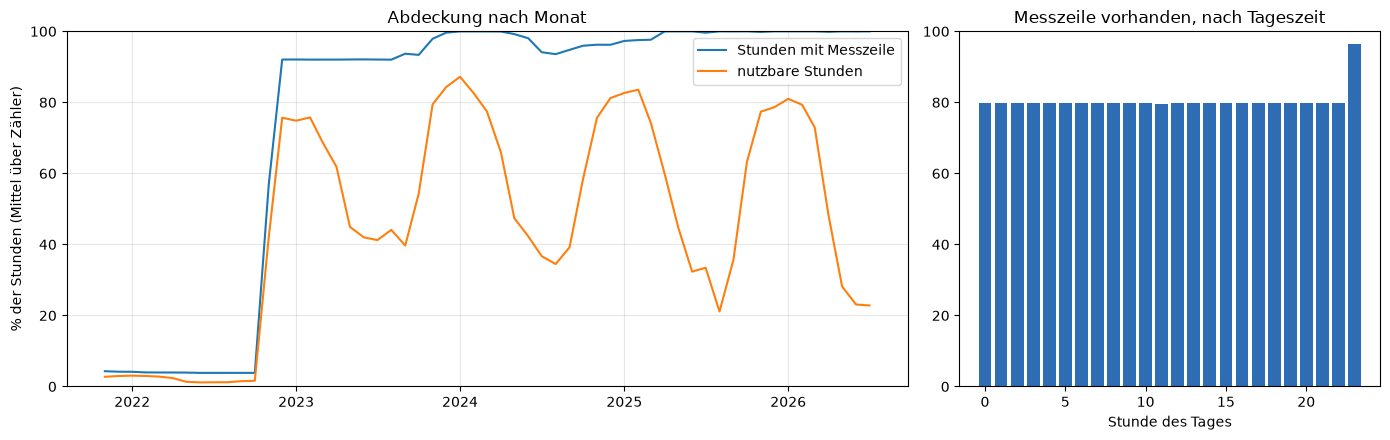

In [30]:


adr = tab.drop_duplicates("zaehler").set_index("zaehler")["adresse"].to_dict()

#1) Der Zähler mit negativer Spreizung
neg = ok_t[ok_t["anteil_negativ"] > 0.1][["zaehler", "anteil_negativ", "vor_median", "rueck_median"]].copy()
neg["adresse"] = neg["zaehler"].map(adr)
display(neg)
print("Zähler ohne Wert bei 'leistung_passt' oder 'abw_zu_geraet_K' (dort lief die Prüfung leer):",
      int(ok_t["leistung_passt"].isna().sum()), "/", int(ok_t["abw_zu_geraet_K"].isna().sum()))

#2) Wodurch geht jede Stunde verloren?
def kategorien(d):
    keine = d[["vor", "rueck", "fluss", "leistung"]].isna().all(axis=1)          #gar keine Messzeile
    tfehlt = (~keine) & (d["vor"].isna() | d["rueck"].isna())                    #Zeile da, Temperatur fehlt
    kfluss = (~keine) & (~tfehlt) & d["fluss"].le(FLUSS_MIN_LH)                  #Temperatur da, kein Durchfluss
    nutz = d["spreizung"].notna()
    return keine, tfehlt, kfluss, nutz

def luecken(maske):
    runs = maske.ne(maske.shift()).cumsum()
    g = maske.groupby(runs).agg(["first", "sum"])
    return g.loc[g["first"], "sum"]

zeilen, alle_luecken, monat_keine, monat_nutz = [], [], {}, {}
std = pd.DataFrame(0.0, index=range(24), columns=["fehlt", "n"])
for z, d in serien.items():
    keine, tfehlt, kfluss, nutz = kategorien(d)
    zeilen.append({"zaehler": z, "keine_zeile": keine.mean(), "temp_fehlt": tfehlt.mean(),
                   "kein_fluss": kfluss.mean(), "nutzbar": nutz.mean()})
    alle_luecken += list(luecken(keine))
    monat_keine[z] = keine.resample("MS").mean()
    monat_nutz[z] = nutz.resample("MS").mean()
    g = keine.groupby(keine.index.hour).agg(["sum", "count"])
    std["fehlt"] += g["sum"].reindex(range(24)).fillna(0)
    std["n"] += g["count"].reindex(range(24)).fillna(0)

K = pd.DataFrame(zeilen).set_index("zaehler")
print(f"\nAnteil aller Stunden (Median über die {len(serien)} Zähler), in Prozent:")
print((K.median() * 100).round(1).rename({"keine_zeile": "keine Messzeile", "temp_fehlt": "Zeile da, Temperatur fehlt",
                                          "kein_fluss": f"kein Durchfluss (≤ {FLUSS_MIN_LH} l/h)",
                                          "nutzbar": "nutzbar"}).to_string())

#3) Wie lang sind die Lücken?
L = pd.Series(alle_luecken, dtype=float)
if len(L):
    kl = pd.cut(L, [0, 3, 24, 168, np.inf], labels=["≤ 3 h", "4–24 h", "1–7 Tage", "> 7 Tage"])
    tab_l = pd.DataFrame({"anzahl": L.groupby(kl, observed=False).size(),
                          "anteil_der_fehlenden_stunden_%": (L.groupby(kl, observed=False).sum() / L.sum() * 100).round(0)})
    print("\nLücken ohne Messzeile nach Länge:")
    display(tab_l)

#4) Durchfluss-Verteilung (zur Kontrolle der Grenze)
f = pd.concat([d["fluss"].dropna() for d in serien.values()])
print("\nDurchfluss in l/h, Quantile 10/25/50/75/90 %:", f.quantile([.1, .25, .5, .75, .9]).round(0).tolist())
print(f"Anteil der vorhandenen Stunden: ≤ 10 l/h: {(f <= 10).mean():.0%} | ≤ 50 l/h: {(f <= 50).mean():.0%}")

#5) Grafiken: Abdeckung nach Monat und nach Tageszeit
MK, MN = pd.DataFrame(monat_keine), pd.DataFrame(monat_nutz)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(MK.index, (1 - MK.mean(axis=1)) * 100, label="Stunden mit Messzeile")
ax[0].plot(MN.index, MN.mean(axis=1) * 100, label="nutzbare Stunden")
ax[0].set_ylim(0, 100); ax[0].set_ylabel("% der Stunden (Mittel über Zähler)"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[0].set_title("Abdeckung nach Monat")
ax[1].bar(std.index, (1 - std["fehlt"] / std["n"]) * 100, color="#2e6db3")
ax[1].set_ylim(0, 100); ax[1].set_xlabel("Stunde des Tages"); ax[1].set_title("Messzeile vorhanden, nach Tageszeit")
plt.tight_layout(); plt.savefig("abdeckung.png", dpi=150); plt.show()

- Im Median über die Zähler fehlt in 9,6 % der Stunden die Messzeile, in 29,1 % fließt kein Wasser (bis 10 l/h). Nutzbar sind 59,4 %.
- 82 % der fehlenden Stunden liegen in Lücken von 4 bis 24 Stunden, 18 % in Lücken über 7 Tage.
- Zähler 80912182 hat in 14,6 % der Stunden negative Spreizung (Vorlauf-Median 75,2 °C, Rücklauf-Median 73,9 °C).

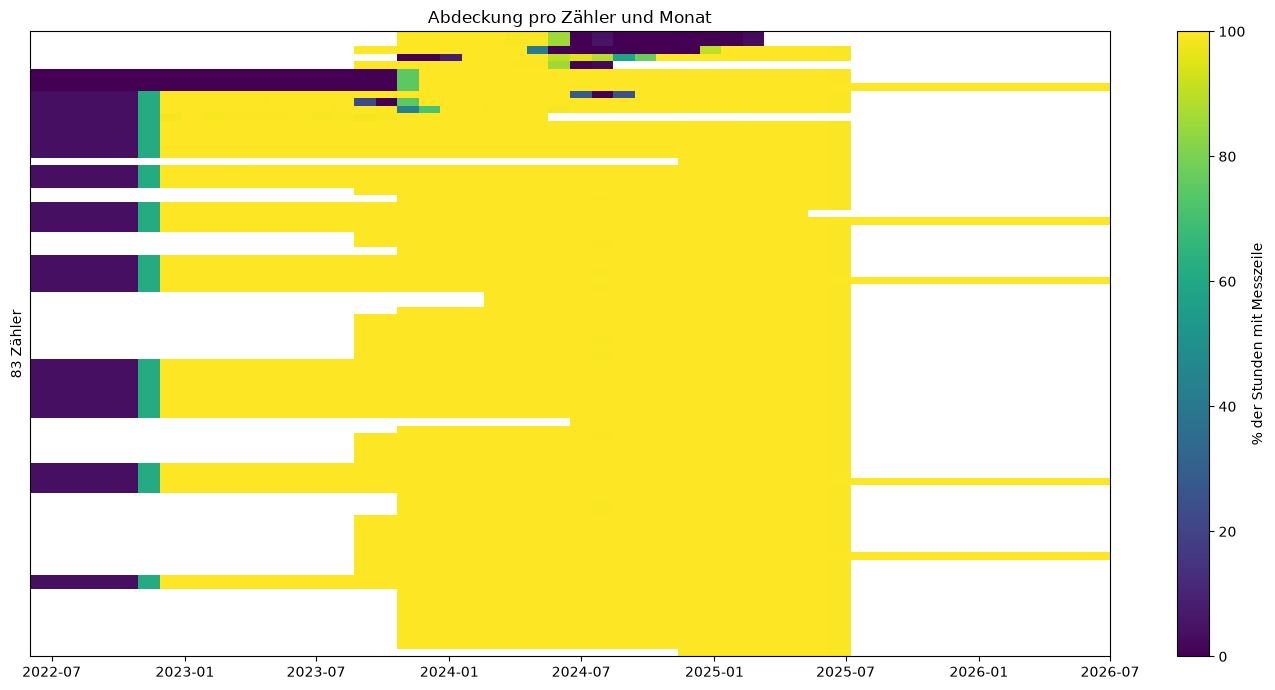

Erste Messzeile je Zähler, nach Monat:
2021-11    36
2022-02     1
2022-05     1
2023-09    23
2023-11    17
2024-01     1
2024-03     2
2024-07     1
2024-12     2
Freq: M

Letzte Messzeile je Zähler, nach Monat:
2024-05     1
2024-08     1
2025-03     2
2025-05     1
2025-07    74
2026-07     5
Freq: M

Messzeilen bis 30.09.2022 insgesamt: 11778
Davon nach Stunde des Tages (häufigste 5): {23: 11772, 22: 3, 11: 1, 16: 1, 10: 1}

Zähler 80912182: Vorlauf-Median 75.2 °C | Rücklauf-Median 73.9 °C
Anteil negativer Spreizung je Quartal:
Timestamp
2023Q3    0.39
2023Q4    0.10
2024Q1    0.02
2024Q2    0.25
2024Q3    0.25
2024Q4    0.06
2025Q1    0.02
2025Q2    0.23
2025Q3    0.41
Freq: Q-DEC

Spreizung in K nach Durchfluss (l/h), alle Zähler:
             count   p25  median   p75
f                                     
0         521440.0   1.5     6.4  14.6
bis 10     46558.0   9.5    21.0  31.5
10–30      94582.0  12.7    21.2  31.5
30–50     108871.0  13.3    28.5  35.5
50–100    206306.0

In [31]:


#1) Abdeckung pro Zähler und Monat: gemeinsamer Ausfall oder einzelne Zähler?
cov = pd.DataFrame({z: d["vor"].notna().resample("MS").mean() for z, d in serien.items()}).loc["2022-06":]
reihenfolge = cov.loc["2023-08":"2025-05"].mean().sort_values().index
x = mdates.date2num(cov.index.to_pydatetime())
fig, ax = plt.subplots(figsize=(14, 7))
im = ax.imshow(cov[reihenfolge].T.values * 100, aspect="auto", cmap="viridis", vmin=0, vmax=100,
               extent=[x[0], x[-1], len(reihenfolge), 0], interpolation="nearest")
ax.xaxis_date(); ax.set_yticks([]); ax.set_ylabel("83 Zähler")
fig.colorbar(im, ax=ax, label="% der Stunden mit Messzeile")
ax.set_title("Abdeckung pro Zähler und Monat")
plt.tight_layout(); plt.savefig("abdeckung_pro_zaehler.png", dpi=150); plt.show()

#2) Wann beginnt und endet jeder Zähler, und was kam in der frühen Phase an?
erste = pd.Series({z: d["vor"].first_valid_index() for z, d in serien.items()})
letzte = pd.Series({z: d["vor"].last_valid_index() for z, d in serien.items()})
print("Erste Messzeile je Zähler, nach Monat:")
print(erste.dt.to_period("M").value_counts().sort_index().to_string())
print("\nLetzte Messzeile je Zähler, nach Monat:")
print(letzte.dt.to_period("M").value_counts().sort_index().to_string())

frueh = pd.concat([d.loc[:"2022-09-30"].dropna(subset=["vor"]) for d in serien.values()])
print("\nMesszeilen bis 30.09.2022 insgesamt:", len(frueh))
print("Davon nach Stunde des Tages (häufigste 5):", frueh.index.hour.value_counts().head(5).to_dict())

#3) Der Zähler mit negativer Spreizung
z = "80912182"
d = serien[z]
s = d["spreizung"].dropna()
print(f"\nZähler {z}: Vorlauf-Median {d['vor'].median():.1f} °C | Rücklauf-Median {d['rueck'].median():.1f} °C")
print("Anteil negativer Spreizung je Quartal:")
print((s < 0).groupby(s.index.to_period("Q")).mean().round(2).to_string())

#4) Ab welchem Durchfluss ist die Spreizung aussagekräftig?
alle = pd.concat([pd.DataFrame({"s": d["vor"] - d["rueck"], "f": d["fluss"]}).dropna() for d in serien.values()])
klassen = pd.cut(alle["f"], [-0.1, 0.5, 10, 30, 50, 100, 200, 1e9],
                 labels=["0", "bis 10", "10–30", "30–50", "50–100", "100–200", "über 200"])
print("\nSpreizung in K nach Durchfluss (l/h), alle Zähler:")
print(alle.groupby(klassen, observed=False)["s"]
      .describe(percentiles=[.25, .5, .75]).round(1)[["count", "25%", "50%", "75%"]]
      .rename(columns={"25%": "p25", "50%": "median", "75%": "p75"}).to_string())

- 36 Zähler liefern seit November 2021, bis Ende September 2022 fast nur den Wert um 23 Uhr.
- 40 Zähler beginnen im September oder November 2023, dazu kommen 8 Nachzügler.
- 74 Zähler laufen bis Juli 2025, 5 bis Juli 2026 (ODS-Nachlieferung), 5 enden früher (zwischen Mai 2024 und Mai 2025).
- Bei Zähler 80912182 tritt die negative Spreizung in jedem Quartal auf (2 bis 41 % der Stunden).

In [32]:
FLUSS_MIN_LH    = 0.5
MIN_STUNDEN_TAG = 6
GEWICHTET       = True

#1) Spreizung und Tageswerte aus den geladenen Reihen neu berechnen
tage = {}
for z, d in serien.items():
    s = (d["vor"] - d["rueck"]).where(d["fluss"] > FLUSS_MIN_LH)
    d["spreizung"] = s
    g = s.notna()
    med = s.resample("D").median()
    if GEWICHTET:
        w = d["fluss"].where(g)
        t_ = (s * w).resample("D").sum(min_count=1) / w.resample("D").sum(min_count=1)
        t_ = t_.fillna(med)
    else:
        t_ = med
    tage[z] = t_.where(g.resample("D").sum() >= MIN_STUNDEN_TAG)
tag = pd.DataFrame(tage)
print("Tageswerte:", tag.shape[0], "Tage x", tag.shape[1], "Zähler")

#2) Phasen: fehlen einzelne Stunden oder ganze Tage?
phasen = {"Jan 2024 – Nov 2024": ("2024-01-01", "2024-11-30"),
          "Dez 2024 – Mai 2025": ("2024-12-01", "2025-05-31"),
          "Jun 2025 – Nov 2025": ("2025-06-01", "2025-11-30")}
zeilen = []
for name, (a, b) in phasen.items():
    h_alle, h_mit, anteil = [], [], []
    for z, d in serien.items():
        x = d.loc[a:b, "vor"].notna()
        if x.sum() == 0:
            continue
        pro_tag = x.groupby(x.index.date).sum()
        h_alle.append(pro_tag.median())
        h_mit.append(pro_tag[pro_tag > 0].median())
        anteil.append((pro_tag > 0).mean())
    zeilen.append({"phase": name,
                   "Stunden pro Tag (Median)": round(float(np.median(h_alle)), 1),
                   "Stunden pro Tag mit Daten": round(float(np.median(h_mit)), 1),
                   "Anteil Tage mit Daten": round(float(np.mean(anteil)), 2)})
display(pd.DataFrame(zeilen))

Tageswerte: 1723 Tage x 84 Zähler


,phase,Stunden pro Tag (Median),Stunden pro Tag mit Daten,Anteil Tage mit Daten
0,Jan 2024 – Nov 2024,24.0,24.0,0.97
1,Dez 2024 – Mai 2025,24.0,24.0,0.97
2,Jun 2025 – Nov 2025,24.0,24.0,1.00


- Tage mit Daten: Januar bis November 2024 und Dezember 2024 bis Mai 2025 je 97 %. Für Juni bis November 2025 zählen nur die Tage bis zum Ende der Reihen (meist Juli 2025).

## 11 Spreizung auf dem Netz

- Nodes ohne Position bekommen eine geschätzte Lage aus ihren Nachbarn im Graphen.
- Karte und Rangliste zeigen die Spreizung je Station über den ganzen Zeitraum.

In [33]:
G = nx.DiGraph()
G.add_edges_from(zip(ek["von_key"], ek["nach_key"]))
U = G.to_undirected()
unbek = [n for n in G if n not in koord]

#Positionen: bekannte übernehmen, unbekannte in die Mitte ihrer Nachbarn setzen
pos = dict(koord)
for comp in nx.connected_components(U):
    bekannt = [pos[n] for n in comp if n in koord]
    if not bekannt:
        continue
    start = tuple(np.mean(bekannt, axis=0))
    for n in comp:
        pos.setdefault(n, start)
for _ in range(300):
    for n in unbek:
        if n in pos:
            nb = [pos[m] for m in U[n] if m in pos]
            if nb:
                pos[n] = tuple(np.mean(nb, axis=0))
geschaetzt = [n for n in unbek if n in pos]

print(f"Nodes: {G.number_of_nodes()} | mit echter Position: {len(koord)} | geschätzt: {len(geschaetzt)} "
      f"| ohne Position: {len(unbek) - len(geschaetzt)}")
print("pos ist:", type(pos).__name__, "mit", len(pos), "Einträgen")

Nodes: 110 | mit echter Position: 93 | geschätzt: 17 | ohne Position: 0
pos ist: dict mit 110 Einträgen


- 93 von 110 Nodes haben eine echte Position, 17 sind geschätzt.

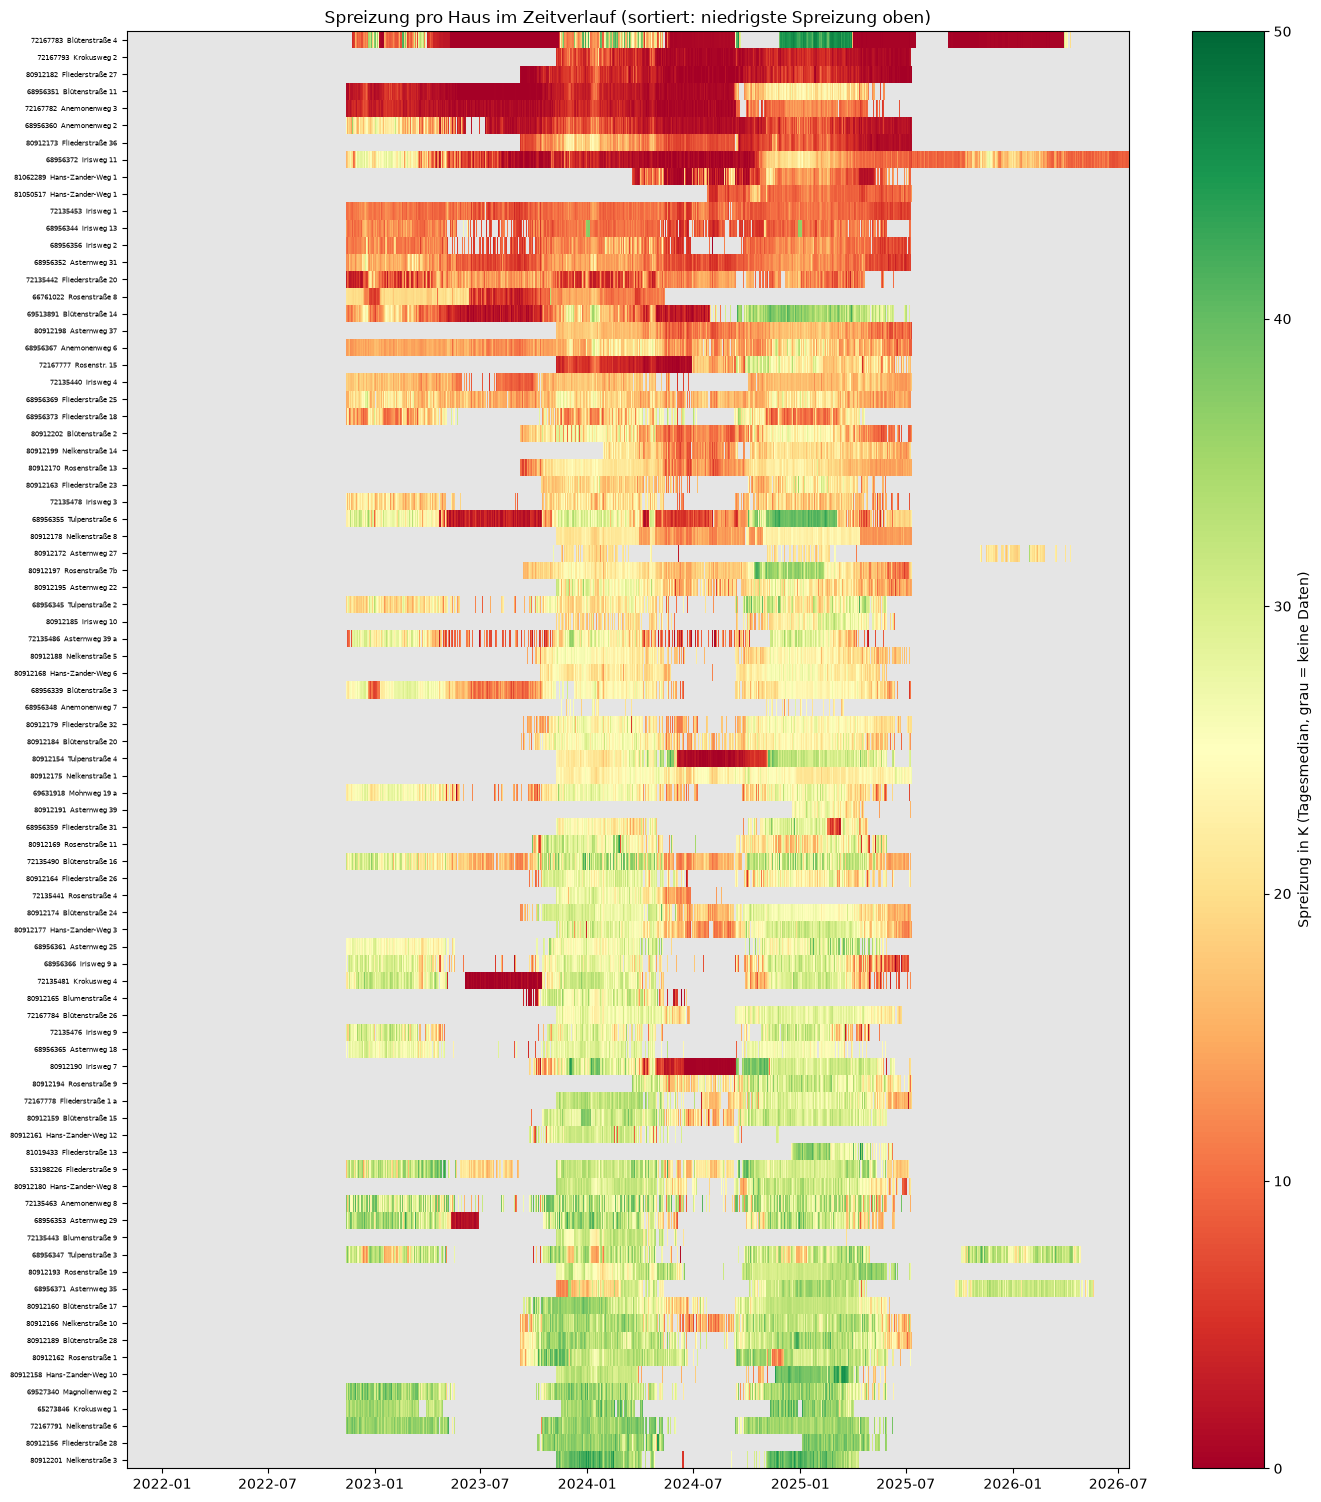

interactive(children=(Dropdown(description='Zähler', options=(('72167783  Blütenstraße 4', '72167783'), ('7216…

,adresse,spreizung_median_K,spreizung_p10_K,spreizung_p90_K,tage_mit_daten
72167783,Blütenstraße 4,0.8,0.1,42.8,1104
72167793,Krokusweg 2,2.4,0.3,7.1,611
80912182,Fliederstraße 27,2.6,-0.0,6.8,673
68956351,Blütenstraße 11,2.7,0.1,21.7,902
72167782,Anemonenweg 3,2.8,0.6,11.7,892
68956360,Anemonenweg 2,4.7,1.2,18.9,936
80912173,Fliederstraße 36,8.3,1.8,17.7,672
81062289,Hans-Zander-Weg 1,9.3,0.9,16.3,449
68956372,Irisweg 11,9.3,0.8,21.4,1346
81050517,Hans-Zander-Weg 1,9.6,7.3,12.6,351


In [34]:
VMIN, VMAX = 0, 50            #Farbskala der Spreizung in K
ZEITRAUM = (None, None)       #z.B. ("2026-01-01", "2026-03-31") für die Karte und das Ranking

adr = tab.drop_duplicates("zaehler").set_index("zaehler")["adresse"].to_dict()
t = tag.loc[ZEITRAUM[0]:ZEITRAUM[1]]
reihenfolge = t.median().sort_values().index

#1) Heatmap: eine Zeile pro Zähler, eine Spalte pro Tag
H = t[reihenfolge].T
cmap = plt.get_cmap("RdYlGn").copy(); cmap.set_bad("#e5e5e5")
x = mdates.date2num(H.columns.to_pydatetime())
fig, ax = plt.subplots(figsize=(14, max(6, 0.18 * len(H))))
im = ax.imshow(H.values, aspect="auto", cmap=cmap, vmin=VMIN, vmax=VMAX,
               extent=[x[0], x[-1], len(H), 0], interpolation="nearest")
ax.xaxis_date()
ax.set_yticks(np.arange(len(H)) + 0.5)
ax.set_yticklabels([f"{z}  {str(adr.get(z, ''))[:24]}" for z in H.index], fontsize=5)
fig.colorbar(im, ax=ax, label="Spreizung in K (Tagesmedian, grau = keine Daten)")
ax.set_title("Spreizung pro Haus im Zeitverlauf (sortiert: niedrigste Spreizung oben)")
plt.tight_layout(); plt.savefig("spreizung_heatmap.png", dpi=150); plt.show()

#2) Ein Haus im Detail: Vorlauf, Rücklauf und Spreizung
def zeige(zaehler, von=None, bis=None, frequenz="1h"):
    z = norm_z(zaehler)
    d = serien[z].loc[von:bis, ["vor", "rueck", "spreizung"]].resample(frequenz).mean()
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(13, 6), gridspec_kw={"height_ratios": [2, 1]})
    a1.plot(d.index, d["vor"], color="#d6402d", lw=0.9, label="Vorlauf")
    a1.plot(d.index, d["rueck"], color="#2e6db3", lw=0.9, label="Rücklauf")
    a1.set_ylabel("°C"); a1.legend(loc="upper right"); a1.grid(alpha=0.3)
    a1.set_title(f"Zähler {z} | {adr.get(z, '')}")
    a2.plot(d.index, d["spreizung"], color="black", lw=0.8); a2.axhline(0, color="gray", lw=0.8)
    a2.set_ylabel("Spreizung in K"); a2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

try:
    import ipywidgets as widgets
    dd = widgets.Dropdown(options=[(f"{z}  {adr.get(z, '')}", z) for z in reihenfolge], description="Zähler")
    widgets.interact(lambda zaehler: zeige(zaehler), zaehler=dd)
except ImportError:
    print("Auswahlfeld: %pip install ipywidgets. Ohne geht auch:  zeige('Zählernummer')")

#3) Ranking
rang = pd.DataFrame({"adresse": [adr.get(z, "") for z in t.columns],
                     "spreizung_median_K": t.median().round(1).values,
                     "spreizung_p10_K": t.quantile(0.1).round(1).values,
                     "spreizung_p90_K": t.quantile(0.9).round(1).values,
                     "tage_mit_daten": t.notna().sum().values}, index=t.columns).sort_values("spreizung_median_K")
display(rang.head(15))
rang.to_csv("spreizung_ranking.csv", sep=";", encoding="utf-8-sig")

#4) Karte: Punkte nach mittlerer Spreizung gefärbt
med = t.median()
kn = knoten.copy()
kn["spreizung"] = kn["zaehler"].apply(lambda s: pd.Series([med.get(norm_z(z), np.nan) for z in s.split(", ")]).mean())
cm = branca.colormap.LinearColormap(["#d73027", "#fee08b", "#1a9850"], vmin=VMIN, vmax=VMAX,
                                    caption="Spreizung in K (Median im gewählten Zeitraum)")
karte_s = folium.Map(location=[kn["lat"].mean(), kn["lon"].mean()], zoom_start=17, tiles="OpenStreetMap")
if "G" in globals() and isinstance(globals().get("pos"), dict):      #Kanten als Hintergrund, falls vorhanden
    for v, w in G.edges:
        if v in pos and w in pos:
            folium.PolyLine([pos[v], pos[w]], color="#999999", weight=2, opacity=0.6).add_to(karte_s)
for r in kn.itertuples():
    farbe = "#888888" if pd.isna(r.spreizung) else cm(r.spreizung)
    folium.CircleMarker([r.lat, r.lon], radius=7 + 2 * min(r.anzahl - 1, 4), color="black", weight=1,
                        fill=True, fill_color=farbe, fill_opacity=0.95,
                        tooltip=f"{r.adresse} | Spreizung: {'keine Daten' if pd.isna(r.spreizung) else f'{r.spreizung:.1f} K'} | Zähler: {r.zaehler}").add_to(karte_s)
cm.add_to(karte_s)
b = kn[["lat", "lon"]].agg(["min", "max"])
karte_s.fit_bounds([[b.loc["min", "lat"], b.loc["min", "lon"]], [b.loc["max", "lat"], b.loc["max", "lon"]]])
karte_s.save("karte_spreizung.html")
display(karte_s)

- Die kleinste mittlere Spreizung liegt bei 0,8 K (Zähler 72167783), danach 72167793 mit 2,4 K. Mehrere Stationen liegen unter 5 K.
- Kleine Spreizung heißt: Das Wasser kommt kaum abgekühlt zurück. Das ist ein Hinweis auf schlechte Auskühlung, noch kein Befund.

## 12 Dashboard-Export

- `dashboard_export.py` baut eine HTML-Karte mit Zeitregler (`fernwaerme_dashboard.html`).
- Die Datei enthält Adressen und Zählerdaten und bleibt intern.

In [35]:
%run -i dashboard_export.py

Hintergrund: 109 Gebäudelinien (Typ 6), 743 Rohrplan-Linien (Shapefile und KML)
Kanten auf Rohren: 105 von 110 | zu weit vom Rohrnetz: 0 | ohne Rohrverbindung: 5 (diese bleiben gerade Linien)
Geschrieben: /Users/ivelinayaneva/projektseminar/notebooks/fernwaerme_dashboard.html  (10.6 MB)
Zeitraum: 2024-01-01 00:00:00 bis 2025-05-31 23:00:00 (12408 Stunden)
Häuser mit Zeitreihe: 79 | Nodes: 110 | Kanten: 110
Graph ist ohne Kreise: True | Quellen: 7
WARNUNG: 11247 Werte lagen außerhalb des Speicherbereichs und wurden gekappt.
Startzeitpunkt im Dashboard: 2024-01-30 08:00:00
Datei im Browser öffnen (Doppelklick). Karte und Hintergrundkacheln brauchen Internet (Leaflet und Webkarte Bayern).
Hintergrund oben rechts in der Karte umschaltbar. OpenStreetMap geht nur, wenn die Datei über einen lokalen Server geöffnet wird:
  Terminal im Ordner der Datei:  python -m http.server 8000   dann im Browser  http://localhost:8000/fernwaerme_dashboard.html
Achtung: Die Datei enthält Adressen und Zählerda

/Users/ivelinayaneva/projektseminar/notebooks/dashboard_export.py:139: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  cand = np.asarray(idx.month.isin([12, 1, 2]) & (idx.hour == 8) & (idx.dayofweek < 5))


- 105 von 110 Kanten liegen auf Rohren, 5 bleiben gerade Linien.
- Zeitraum der Karte Januar 2024 bis Mai 2025, 79 Häuser mit Zeitreihe.
- 11.247 Werte lagen außerhalb des Speicherbereichs und wurden gekappt.

## 13 Quelle als Annahme aus dem Wärmenetzplan

- Der Wärmenetzplan (PDF in `data/raw/`) zeigt, wo der Erzeuger ungefähr liegt. Diese Lage wird als Annahme übernommen.
- Der Erzeuger bekommt einen eigenen Knoten „Erzeuger (Annahme)“. Die Position ist aus der Karte abgelesen.
- Eine neue Kante verbindet ihn mit dem Node, an dem er vermutlich einspeist.
- Danach werden die Objekte für Notebook 32 und 37 gespeichert (`daten_cache/paket.pkl`) und das Graph-Schema als Bild.

In [36]:
suche = "Hans-Zander-Weg 1"        #Teil der Straße oder des Namens
treffer = [(n, roh.get(n, n)) for n in G if suche.lower() in str(roh.get(n, n)).lower()]
for n, name in treffer:
    print(repr(n), "->", name, "| Nachfolger:", len(list(G.successors(n))))

'hans-zander-weg 1' -> Hans-Zander-Weg 1 | Nachfolger: 1
'hans-zander-weg 14' -> Hans-Zander-Weg 14 | Nachfolger: 1
'hans-zander-weg 12' -> Hans-Zander-Weg 12 | Nachfolger: 1
'hans-zander-weg 10' -> Hans-Zander-Weg 10 | Nachfolger: 2


In [37]:
QUELLE = "Erzeuger (Annahme)"
QUELLE_POS = (49.79730660186304, 10.347117955779149)    #(lat, lon) der vermuteten Einspeisestelle, aus der Karte abgelesen
ANSCHLUSS = ['hans-zander-weg 1']                      #Nodes, an die er einspeist; leer = alle bisherigen Startknoten

if "G_orig" not in globals():
    G_orig = G.copy()               #Original einmalig sichern
G = G_orig.copy()
starts = ANSCHLUSS or [n for n in G_orig if G_orig.in_degree(n) == 0]
G.add_node(QUELLE)
for s in starts:
    G.add_edge(QUELLE, s)
pos[QUELLE] = QUELLE_POS
roh[QUELLE] = QUELLE
print("Quelle speist ein in:", [roh.get(s, s) for s in starts])

Quelle speist ein in: ['Hans-Zander-Weg 1']


In [38]:
import os
os.makedirs("daten_cache", exist_ok=True)
paket = {n: globals()[n] for n in ("serien", "knoten", "G", "pos", "roh", "linien", "kml_linien", "geschaetzt")
         if n in globals()}
pd.to_pickle(paket, Path("daten_cache") / "paket.pkl")
print("Gespeichert in", Path("daten_cache").resolve(), "|", sorted(paket))

Gespeichert in /Users/ivelinayaneva/projektseminar/notebooks/daten_cache | ['G', 'geschaetzt', 'kml_linien', 'knoten', 'linien', 'pos', 'roh', 'serien']




Gespeichert: graph_schema.png | Nodes ohne Position (im Dashboard nicht sichtbar): 0


In [39]:



DATEI = "graph_schema.png"       #wird zusätzlich neben dem Notebook gespeichert
KURZ = 24                        #Beschriftung auf so viele Zeichen kürzen

mit_zaehler = set(knoten["edge_node"])
ohne_pos = {n for n in G if n not in pos}
starts = {n for n in G if G.in_degree(n) == 0}
H = G.copy()

ist_dag = nx.is_directed_acyclic_graph(H)
if ist_dag:
    gen = list(nx.topological_generations(H))
    for i, schicht in enumerate(gen):
        for n in schicht:
            H.nodes[n]["schicht"] = i
    xy = nx.multipartite_layout(H, subset_key="schicht", align="vertical")
    art = "geschichtet: links Startknoten, rechts Endhäuser"
    breite, hoehe = max(14, 2.2 * len(gen)), max(8, 0.45 * max(len(g) for g in gen))
else:
    xy = nx.spring_layout(H.to_undirected(), seed=1, k=0.6)
    art = "freie Anordnung (Graph hat Kreise)"
    breite, hoehe = 16, 12

fig, ax = plt.subplots(figsize=(breite, hoehe))
nx.draw_networkx_edges(H, xy, ax=ax, arrows=True, arrowstyle="-|>", arrowsize=12,
                       edge_color="#6b7785", width=1.1, node_size=380, connectionstyle="arc3,rad=0.05")
farben = ["#2e6db3" if n in mit_zaehler else "#d5dce3" for n in H]
rand = ["#e11d48" if n in starts else "#222222" for n in H]
nx.draw_networkx_nodes(H, xy, ax=ax, node_color=farben, edgecolors=rand, node_size=380,
                       linewidths=[2.5 if n in starts else 0.8 for n in H])
labels = {n: str(roh.get(n, n))[:KURZ] for n in H}
ylen = max(y for _, y in xy.values()) - min(y for _, y in xy.values()) or 1
xy_l = {n: (x, y + 0.025 * ylen) for n, (x, y) in xy.items()}
nx.draw_networkx_labels(H, xy_l, labels=labels, font_size=6, ax=ax,
                        verticalalignment="bottom", bbox=dict(fc="white", ec="none", alpha=0.7, pad=0.3))
ax.set_title(f"Netzgraph ({art}) – {H.number_of_nodes()} Nodes, {H.number_of_edges()} Kanten", fontsize=11)
ax.axis("off")
ax.legend(handles=[
    plt.Line2D([], [], marker="o", ls="", mfc="#2e6db3", mec="#222", label=f"Haus mit Zähler ({len(mit_zaehler & set(H))})"),
    plt.Line2D([], [], marker="o", ls="", mfc="#d5dce3", mec="#222", label="Abzweig / Punkt ohne Zähler"),
    plt.Line2D([], [], marker="o", ls="", mfc="white", mec="#e11d48", mew=2.5, label=f"Startknoten ohne eingehende Kante ({len(starts)})"),
], loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(DATEI, dpi=150)
plt.show()
print("Gespeichert:", DATEI, "| Nodes ohne Position (im Dashboard nicht sichtbar):", len(ohne_pos))

## 14 Stimmt die Pfeilrichtung der Kantendatei?

- Die Kanten werden vom Einspeise-Node aus neu ausgerichtet und mit der Datei verglichen.
- Prüfung mit Messdaten: Der Vorlauf kühlt auf dem Weg ab, also sollte er in Pfeilrichtung sinken.
- Bewertet werden Start- gegen Endknoten und jede Kante mit Zählern an beiden Enden (Heizsaison November bis März, Unterschiede unter 0,5 K gelten als unklar).

In [40]:
ANFANG = 'hans-zander-weg 1'                        #Node, an dem die Quelle anliegt (Name wie im Graphen)
U = G_orig.to_undirected()
T = nx.bfs_tree(U, ANFANG)          #Kanten zeigen vom Anfang weg
gedreht = [(u, v) for u, v in G_orig.edges if T.has_edge(v, u)]
print(len(gedreht), "Kanten laufen entgegen der Datei:", gedreht)

52 Kanten laufen entgegen der Datei: [('krokusweg 4', 'krokusweg 2'), ('krokusweg 2', 'irisweg 13'), ('krokusweg 1', 'krokusweg 2'), ('irisweg 13', 'anemonenweg 8'), ('anemonenweg 8', 'anemonenweg 7'), ('ginsterweg 24', 'irisweg 10'), ('irisweg 10', 'anemonenweg 8'), ('irisweg 11', 'anemonenweg 8'), ('ginsterweg 6', 'ginsterweg 14'), ('ginsterweg 14', 'anemonenweg 7'), ('anemonenweg 7', 'anemonenweg 6'), ('anemonenweg 6', 'anemonenweg 5'), ('anemonenweg 5', 'anemonenweg 4'), ('anemonenweg 4', 'anemonenweg 3'), ('anemonenweg 3', 'anemonenweg 2'), ('anemonenweg 2', 'anemonenweg 1'), ('mohnweg 21', 'anemonenweg 1'), ('anemonenweg 1', 'asternweg 29'), ('asternweg 29', 'asternweg 18'), ('asternweg 18', 'asternweg 27'), ('asternweg 27', 'asternweg 25'), ('asternweg 25', 'fliederstrasse 18'), ('fliederstrasse 18', 'bluetenstrasse 16'), ('irisweg 9a', 'irisweg 9'), ('irisweg 9', 'irisweg 8'), ('irisweg 8', 'irisweg 7'), ('irisweg 7', 'irisweg 6'), ('irisweg 6', 'irisweg 5'), ('irisweg 5', 'iri

In [41]:

MIN_FLUSS = 5          #l/h: nur Stunden mit echtem Durchfluss zählen

G0 = G_orig if "G_orig" in globals() else G
starts = [n for n in G0 if G0.in_degree(n) == 0 and G0.out_degree(n) > 0]   #nur ausgehende Kanten
enden = [n for n in G0 if G0.out_degree(n) == 0 and G0.in_degree(n) > 0]    #nur eingehende Kanten
einzeln = [n for n in G0 if G0.in_degree(n) == 0 and G0.out_degree(n) == 0]
print(f"Startknoten (nur ausgehend): {len(starts)} | Endknoten (nur eingehend): {len(enden)} | isoliert: {len(einzeln)}")

nz = norm_z if "norm_z" in globals() else (lambda s: "".join(ch for ch in str(s) if ch.isdigit()).lstrip("0"))
zaehler_von = {r.edge_node: [nz(z) for z in str(r.zaehler).split(",") if nz(z)] for r in knoten.itertuples()}

def mittel_vorlauf(n):
    teile = []
    for z in zaehler_von.get(n, []):
        if z in serien:
            d = serien[z]
            teile.append(d.loc[d["fluss"] > MIN_FLUSS, "vor"])
    s = pd.concat(teile) if teile else pd.Series(dtype=float)
    return s.mean() if len(s) else np.nan

vor = pd.Series({n: mittel_vorlauf(n) for n in G0}).dropna()
print("\nMittlerer Vorlauf (°C) bei Durchfluss > %s l/h" % MIN_FLUSS)
for name, gruppe in (("Startknoten", starts), ("Endknoten", enden)):
    w = vor.reindex(gruppe).dropna()
    print(f"  {name:12s}: {w.mean():6.1f}  (n={len(w)})" if len(w) else f"  {name:12s}: keine Messwerte")

if nx.is_directed_acyclic_graph(G0):
    stufe = {n: i for i, g in enumerate(nx.topological_generations(G0)) for n in g}
    t = pd.DataFrame({"stufe": pd.Series(stufe), "vor": vor}).dropna()
    r = t["stufe"].corr(t["vor"], method="spearman")
    print(f"\nKorrelation Stufe im Graph und Vorlauf (Spearman): {r:.2f}  (n={len(t)})")
    print("Negativ = Vorlauf sinkt in Pfeilrichtung (Richtung plausibel). Positiv = Richtung eher umgekehrt.")
else:
    print("\nGraph hat Kreise: Stufenvergleich nicht möglich.")

Startknoten (nur ausgehend): 7 | Endknoten (nur eingehend): 13 | isoliert: 0

Mittlerer Vorlauf (°C) bei Durchfluss > 5 l/h
  Startknoten :   63.7  (n=4)
  Endknoten   :   67.9  (n=11)

Korrelation Stufe im Graph und Vorlauf (Spearman): 0.26  (n=79)
Negativ = Vorlauf sinkt in Pfeilrichtung (Richtung plausibel). Positiv = Richtung eher umgekehrt.


In [42]:



MIN_FLUSS = 20          #l/h an BEIDEN Häusern der Kante
MONATE = [11, 12, 1, 2, 3]   #nur Heizsaison, dann ist der Durchfluss hoch und Stichleitungen kühlen kaum aus
MIN_STUNDEN = 100       #Kanten mit weniger gemeinsamen Stunden werden nicht bewertet
SCHWELLE_K = 0.5        #Unterschied in K, ab dem eine Richtung als eindeutig gilt

G0 = G_orig if "G_orig" in globals() else G
nz = norm_z if "norm_z" in globals() else (lambda s: "".join(ch for ch in str(s) if ch.isdigit()).lstrip("0"))
zaehler_von = {r.edge_node: [nz(z) for z in str(r.zaehler).split(",") if nz(z)] for r in knoten.itertuples()}

def vorlauf(n):
    ds = [serien[z] for z in zaehler_von.get(n, []) if z in serien]
    if not ds:
        return None
    f = pd.concat([d["vor"].where(d["fluss"] > MIN_FLUSS) for d in ds], axis=1).mean(axis=1)
    return f[f.index.month.isin(MONATE)]

zeilen = []
for u, v in G0.edges:
    a, b = vorlauf(u), vorlauf(v)
    if a is None or b is None:
        continue
    d = (a - b).dropna()
    if len(d) >= MIN_STUNDEN:
        zeilen.append({"von": roh.get(u, u), "nach": roh.get(v, v), "stunden": len(d),
                       "median_K": round(d.median(), 2), "anteil_von_waermer": round((d > 0).mean(), 2)})
t = pd.DataFrame(zeilen)
n_alle = G0.number_of_edges()
print(f"Kanten gesamt: {n_alle} | beide Enden mit Zähler und genug Daten: {len(t)}")
if len(t):
    ok = (t["median_K"] > SCHWELLE_K).sum()
    umg = (t["median_K"] < -SCHWELLE_K).sum()
    print(f"  Vorlauf sinkt in Pfeilrichtung (Richtung plausibel): {ok}")
    print(f"  Vorlauf steigt in Pfeilrichtung (Richtung verdächtig): {umg}")
    print(f"  kein klarer Unterschied (±{SCHWELLE_K} K): {len(t) - ok - umg}")
    print("\nVerdächtigste Kanten (Vorlauf steigt am stärksten in Pfeilrichtung):")
    display(t.sort_values("median_K").head(10))

Kanten gesamt: 110 | beide Enden mit Zähler und genug Daten: 56
  Vorlauf sinkt in Pfeilrichtung (Richtung plausibel): 22
  Vorlauf steigt in Pfeilrichtung (Richtung verdächtig): 26
  kein klarer Unterschied (±0.5 K): 8

Verdächtigste Kanten (Vorlauf steigt am stärksten in Pfeilrichtung):


/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39565/4226321258.py:14: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  f = pd.concat([d["vor"].where(d["fluss"] > MIN_FLUSS) for d in ds], axis=1).mean(axis=1)
/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39565/4226321258.py:14: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  f = pd.concat([d["vor"].where(d["fluss"] > MIN_FLUSS) for d in ds], axis=1).mean(axis=1)


,von,nach,stunden,median_K,anteil_von_waermer
0,Krokusweg 4,Krokusweg 2,6534,-10.3,0.00
2,Krokusweg 1,Krokusweg 2,3857,-5.7,0.00
10,Asternweg 29,Asternweg 18,4537,-5.1,0.12
55,Rosenstraße 9,Rosenstraße 8,255,-4.3,0.01
22,Asternweg 35,Asternweg 37,4242,-3.5,0.02
9,Asternweg 29,Asternweg 22,3978,-3.1,0.13
4,Anemonenweg 8,Anemonenweg 7,1014,-3.0,0.12
15,Asternweg 25,Fliederstraße 18,5635,-2.8,0.07
41,Fliederstraße 25,Fliederstraße 27,2935,-2.7,0.02
26,Fliederstraße 13,Fliederstraße 18,2094,-2.7,0.06


- 52 von 110 Kanten zeigen in der Datei zur Quelle hin statt von ihr weg.
- Endknoten haben im Mittel wärmeren Vorlauf als Startknoten (67,9 gegen 63,7 °C). Die Rangkorrelation zwischen Stufe im Graph und Vorlauf ist positiv (0,26).
- Je Kante: Bei 22 von 56 bewertbaren Kanten sinkt der Vorlauf in Pfeilrichtung, bei 26 steigt er, 8 sind unklar.
- Die Pfeile der Kantendatei passen damit nicht verlässlich zur Fließrichtung.

## Zusammenfassung & Bewertung

**Ergebnis**
- Netzmodell aus der Kantendatei: 110 Nodes, 110 Kanten, ein zusammenhängendes Netz mit einem Ring.
- 89 Zähler mit Zeitreihe sind zugeordnet, 84 davon an einer Kante, alle mit Koordinate.
- 105 von 110 Kanten liegen auf den Rohren des Leitungsplans.
- Der Erzeuger ist als Annahme aus dem Wärmenetzplan an das Netz angehängt.

**Belastbar**
- Zuordnung Zähler zu Node über Zählernummer und Adressabgleich, mit Kontrolllisten für alle Abweichungen.
- Rohrdaten (Material, Dimension) für 424 KML-Linien.

**Schwach**
- 865 von 1289 KML-Linien haben keine Rohrart.
- 17 Kanten-Nodes ohne Position, ihre Lage ist geschätzt.
- Die Pfeilrichtung der Kantendatei passt nicht zum Vorlaufgefälle (22 Kanten plausibel, 26 verdächtig).
- Datenlage: Im Median sind 59,4 % der Stunden nutzbar, die meisten Reihen enden im Juli 2025.

**Offen**
- Echte Lage des Erzeugers und Bedeutung der Pfeile mit der ÜZ klären.
- Koordinaten der 17 Nodes ohne Position nachtragen.